# **Certamen I: DeepDetect 2026**
**Integrantes**
<br>
Catalina Cornejo <br>
Hellen Quiñones <br>
Gustavo Sánchez <br>

---


**Problema**
<br>
En la actualidad, con el avance de la inteligencia artificial (IA), el riesgo de caer en estafas ha aumentado debido a la falsificación de identidades mediante imágenes creadas sintéticamente. Estas son cada vez más realistas, lo que dificulta identificar a simple vista si una fotografía es real o creada por IA, lo que representa un riesgo en situaciones donde las imágenes son utilizadas como evidencia o como verificadores de identidades. Frente a esto, el presente trabajo busca apoyar su identificación mediante la clasificación binaria de imágenes digitales según las clases `fake` y `real`.

**Objetivo** <br>
Desarrollar una aplicación web que permita clasificar imágenes faciales como reales o generadas por IA, mostrando el nivel de confianza del modelo y recomendaciones para verificar los resultados.

**Datos**
<br>
 [Deep Detect Dataset 2026](https://www.kaggle.com/datasets/ucimachinelearning/deep-detect-dataset-2026?select=DeepDetect), disponible en Kaggle bajo la cuenta ucimachinelearning.


**Modelos comparados** <br> EfficientNet-B0 y ResNet-50 con *transfer learning* de `timm`.

**Reproducibilidad** <br> semilla: **2026**<br> 70 % entrenamiento <br> 15 % validación <br> 15 % prueba

> **Importante:** los resultados, cantidades, curvas, matriz de confusión, métricas y modelo exportado corresponden a la ejecución del notebook. Por otro lado, la licencia corresponde a la información publicada por la fuente del dataset por lo que el desempeño obtenido representa una evaluación sobre el dataset utilizado y no garantiza resultados equivalentes con imágenes de otras fuentes. Finalmente se recomienda ejecutar en **Google Colab-->Entorno de ejecución-->Cambiar tipo-->GPU T4**.

## 0. Librerías y configuración

Primero instalamos e importamos las librerías necesarias para manipular archivos, procesar imágenes, analizar datos y visualizar resultados. Además, establecemos una semilla de 2026 para controlar la aleatoriedad del entrenamiento y facilitar la reproducibilidad de nuestros experimentos.

- `kagglehub`: para la descarga del dataset.
- `Pillow`, `pandas`, `imagehash`: Para revisar la calidad de los datos antes de el entrenamiento, por ejemplo, ver si una misma imagen está duplicada en  entrenamiento y en validación (auditoría). O para preparar las imágenes para que puedan ingresar al modelo al redimencionarlas. Pillow para comprobar si una imagen funciona y convertirla a RGB, e imagehash para la búsqueda de similitudes en imágenes.

- `torch`, `torchvision`, `timm`: entrenamiento por transferencia de aprendizaje, es decir usar modelos preentrenados en vez de crear uno desde 0, de forma de poder amoldar estos a nuestro caso. Por un lado, torchvision prepara y transforma las imágenes; timm proporciona modelos preentrenados como ResNet-50 y EfficientNet-B0. Y torch ejecuta los cálculos necesarios para entrenar y ajustar estos modelos, permitiendo clasificar las imágenes como REAL o FAKE.

- `scikit-learn`: partición, métricas y matrices de confusión.
- `matplotlib`: visualizaciones en general.

Finalmente, la semilla `"2026"` se aplicará a Python, NumPy y PyTorch.

In [ ]:
!pip -q install kagglehub timm imagehash pandas scikit-learn pillow matplotlib seaborn

# -q sirve para que en la instalación se reduzcan los mensajes
# Los nombres finales son las librerías que queremos utilizar.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 22.5 MB/s eta 0:00:00


In [ ]:
#Librerías para archivos, datos y visualizaciones
import os, json, random, math, hashlib, warnings, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Procesamiento de imágenes y modelos de aprendizaje
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image, ImageOps, UnidentifiedImageError
import timm, kagglehub, imagehash

#División de datos y evaluación
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, fbeta_score, confusion_matrix,
    ConfusionMatrixDisplay, classification_report)

#Semilla para reproducibilidad
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

#Usar GPU si está disponible
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

#Dataset y categorías de clasificación
DATASET_SLUG = 'ucimachinelearning/deep-detect-dataset-2026'

CLASES = ['fake', 'real']  # 0=fake, 1=real: sigmoid devuelve P(real)
#cuando el modelo devuelve una probabilidad mediante sigmoid, se interpreta...
#... como la probabilidad estimada de que la imagen sea REAL,...
#...siempre que se mantenga esa codificación de etiquetas.

IMG_SIZE = 224 # Tamaño de 224x224 píxeles en imágenes

#Parámetros para el entrenamiento
LOTE = 32 if DEVICE.type == 'cuda' else 8 #¿no tienes cpu? Se procesan lotes más pequeños
EPOCAS_CABEZA = 6
EPOCAS_AJUSTE = 3
AJUSTE_FINO = True
NUM_WORKERS = 2

# OJO: Para una primera depuración rápida puede usarse un límite, PERO...
# ...la evaluación final del proyecto debe realizarse sin submuestreos.
MAX_IMAGENES_POR_CLASE = None

#Carpetas donde guardar resultados y modelos
CARPETA_PROYECTO = Path('/content/DeepDetect_2026_proyecto') if Path('/content').exists() else Path.cwd() / 'DeepDetect_2026_proyecto'
RUTA_RESULTADOS = CARPETA_PROYECTO / 'resultados'
RUTA_MODELO = CARPETA_PROYECTO / 'modelo'

RUTA_RESULTADOS.mkdir(parents=True, exist_ok=True)
RUTA_MODELO.mkdir(parents=True, exist_ok=True)
print('Dispositivo:', DEVICE, '| PyTorch:', torch.__version__, '| semilla:', SEED)
print('Consejo: ejecutar con GPU en Colab para reducir el tiempo de entrenamiento.')

if DEVICE.type == 'cuda':
    print('GPU disponible para entrenamiento.')
else:
    print('GPU no detectada. Se utilizará CPU.')


Dispositivo: cuda | PyTorch: 2.11.0+cu130 | semilla: 2026
Consejo: ejecutar con GPU en Colab para reducir el tiempo de entrenamiento.
GPU disponible para entrenamiento.


El entrenamiento de EfficientNet-B0 y ResNet-50 se dividió en dos etapas, utilizando un total de **9 épocas**.

En primer lugar, se establecieron **6 épocas para entrenar la cabeza clasificadora (`EPOCAS_CABEZA = 6`)**. Durante esta etapa, las capas preentrenadas permanecen congeladas y únicamente se ajusta la nueva capa encargada de distinguir entre imágenes reales (`real`) y generadas o manipuladas mediante inteligencia artificial (`fake`).

Posteriormente, se definieron **3 épocas de ajuste fino (`EPOCAS_AJUSTE = 3`)**, durante las cuales se permite actualizar también las últimas capas del modelo preentrenado de forma de adaptar las características previamente aprendidas al conjunto de imágenes utilizado, empleando una tasa de aprendizaje menor.

Además, la elección de 6 y 3 épocas responde a un criterio práctico de eficiencia computacional, considerando el tiempo de ejecución y los recursos disponibles. Asimismo, como se verá más adelante, las curvas obtenidas muestran una disminución progresiva de la pérdida y una mejora en el accuracy, tanto en entrenamiento como en validación, sin evidencias claras de sobreajuste durante las nueve épocas. Cabe destacar que un entrenamiento más prolongado podría producir mejoras adicionales.

### 1. Los datos

El dataset seleccionado es `Deep Detect Dataset 2026`, publicado en Kaggle por el usuario `ucimachinelearning` y desarrollado para la investigación y detección automatizada de imágenes faciales manipuladas o generadas mediante inteligencia artificial.

El conjunto contiene dos categorías: **`real`**, correspondiente a imágenes faciales auténticas y sin manipulación, y **`fake`**, que incluye imágenes generadas o alteradas digitalmente.

Con ello, el dataset cuenta con una **licencia CC0: Public Domain**, que permite su utilización, modificación y distribución sin solicitar autorización previa. No obstante, la ficha no identifica necesariamente a los creadores originales de cada imagen.

Para desarrollar el proyecto, se analizará la cantidad de imágenes por clase, sus dimensiones y posibles desequilibrios, además de revisar la integridad de los archivos antes de dividirlos en los conjuntos de entrenamiento, validación y prueba.

In [ ]:
# Descarga
ruta_descarga = Path(kagglehub.dataset_download(DATASET_SLUG))
print('Directorio de descarga:', ruta_descarga)
print('Primeras entradas:', [p.name for p in list(ruta_descarga.iterdir())[:25]])

# Metadatos públicos: pueden variar según acceso o versión de la API.
# No se inventará una licencia si la API no la entrega.
try:
    import requests
    url_meta = f'https://www.kaggle.com/api/v1/datasets/view/{DATASET_SLUG}'
    r = requests.get(url_meta, timeout=20)
    r.raise_for_status()
    meta = r.json()
 # Extraer los datos relevantes para documentar la fuente
    print('Título:', meta.get('title', 'No disponible'))
    print('Propietario de la ficha:', meta.get('ownerName', meta.get('ownerRef', 'No disponible')))
    print('Licencias publicadas:', meta.get('licenses', meta.get('licenseName', 'No disponible')))
    print('Última actualización:', meta.get('lastUpdated', 'No disponible'))

 # Guardar los metadatos
    (RUTA_RESULTADOS / 'metadatos_kaggle.json').write_text(json.dumps({
        'slug': DATASET_SLUG,
        'titulo': meta.get('title'),
        'licencias': meta.get('licenses', meta.get('licenseName')),
        'actualizacion': meta.get('lastUpdated')}, ensure_ascii=False, indent=2), encoding='utf-8')
except Exception as exc:
    print('No fue posible consultar los metadatos automáticamente:', type(exc).__name__)
    print('Consultar manualmente la sección License en la ficha de Kaggle e incorporarla al README.')

100%|██████████| 735M/735M [00:44<00:00, 17.2MB/s]

Extracting files...


Directorio de descarga: /root/.cache/kagglehub/datasets/ucimachinelearning/deep-detect-dataset-2026/versions/1
Primeras entradas: ['DeepDetect']
Título: Deep Detect Dataset 2026
Propietario de la ficha: UCI Machine Learning
Licencias publicadas: CC0: Public Domain
Última actualización: 2026-08-24T19:55:39.82Z


El dataset se descargó correctamente desde Kaggle. Según los metadatos consultados, fue publicado por UCI Machine Learning, bajo la licencia CC0 (dominio público), y su última actualización corresponde al 24 de agosto de 2026.

Ya habiendo registrado lo anterior, sabemos que los archivos se encuentran dentro de la carpeta DeepDetect, por lo que el siguiente paso será revisar su contenido, identificar las clases y conocer la cantidad y distribución de imágenes disponibles.

### 1.1 Auditoría: revisando todo antes del entrenamiento (carpetas, conteo, archivos ilegibles y posibles duplicados)

Antes de separar las imágenes, la auditoría realiza lo siguiente:

1. Localiza las fotos en la carpeta `fake` o `real`, incluso si el dataset tiene una carpeta contenedora adicional (`DeepDetect`).
2. Verifica que las imágenes puedan abrirse, registra tamaño y extensión.
3. Calcula SHA-256 para identificar **duplicados exactos** (transforma los datos binarios de cada imagen en un código de 256 bits que funciona como una huella digital. Al comparar esos códigos, podemos identificar archivos duplicados y evitar que afecten la evaluación de nuestros modelos).
4. Calcula un hash perceptual (pHash) para agrupar imágenes con el **mismo** resumen perceptual, por ejemplo misma imagen pero con menos luz o detalles levemente cambiados,agrupando aquellas que presentan exactamente el mismo hash perceptual, evitando que queden distribuidas entre entrenamiento, validación y prueba. Este procedimiento **no detecta todos los duplicados cercanos**: versiones recortadas, recomprimidas o generadas desde la misma fuente pueden requerir inspección adicional.
5. Excluye archivos ilegibles y coincidencias de hash que tengan etiquetas contradictorias, conservando un registro.

**Limitación:** esta revisión puede tardar si la colección es grande; se realiza una sola vez, antes de dividir los datos. En esta fase NO se normaliza (no se pasan a valores del 0 al 1) ni aumenta datos (generar variaciones de las imágenes originales, como rotarlas, cambiar su brillo o voltearlas, para ayudar al modelo a generalizar) antes de dividir en train, validation y test

In [ ]:
EXTS = {'.jpg', '.jpeg', '.png', '.webp', '.bmp', '.tif', '.tiff'}
# Definimos qué tipos de archivos reconocerá el programa como imágenes.

# Se asigna una clase a partir de un segmento explícito del directorio.
# Si la ruta incluye ambos nombres, se descarta como ambigua.
def clase_de_ruta(path, root):
    parts = [p.lower() for p in path.relative_to(root).parts[:-1]]
    clases_en_ruta = [c for c in CLASES if c in parts]
    return clases_en_ruta[0] if len(clases_en_ruta) == 1 else None

candidatas = [(p, clase_de_ruta(p, ruta_descarga))
              for p in ruta_descarga.rglob('*') if p.is_file() and p.suffix.lower() in EXTS]
candidatas = sorted([(p, c) for p, c in candidatas if c is not None], key=lambda z: str(z[0]))
assert candidatas, 'No se localizaron imágenes dentro de carpetas fake y real. Inspeccione la estructura descargada.'
if MAX_IMAGENES_POR_CLASE is not None:
    rng = np.random.default_rng(SEED)
    candidatas = sum(([(p,c) for p,c in candidatas if c == cl][:MAX_IMAGENES_POR_CLASE]
                      for cl in CLASES), [])
    print('ADVERTENCIA: se usa un subconjunto. Desactivar el límite para la entrega definitiva.')
print('Archivos detectados antes de auditoría:', len(candidatas))
print('Por clase (antes de limpieza):', pd.Series([c for _, c in candidatas]).value_counts().to_dict())

Archivos detectados antes de auditoría: 21776
Por clase (antes de limpieza): {'real': 11377, 'fake': 10399}


In [ ]:
def sha256_archivo(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1024*1024), b''):
            h.update(chunk)
    return h.hexdigest()

filas, fallidas = [], []
for i, (ruta, clase) in enumerate(candidatas, start=1):
    try:
        with Image.open(ruta) as img:
            img.verify()                 # detectar corrupción del archivo
        with Image.open(ruta) as img:
            img = ImageOps.exif_transpose(img).convert('RGB')
            ancho, alto = img.size
            img.thumbnail((256, 256))    # pHash ligero, sin modificar la original
            ph = str(imagehash.phash(img))
        filas.append({'path': str(ruta), 'class': clase, 'width': ancho, 'height': alto,
                      'ext': ruta.suffix.lower(), 'sha256': sha256_archivo(ruta), 'phash': ph})
    except Exception as exc:
        fallidas.append({'path': str(ruta), 'class': clase, 'error': str(exc)[:250]})
    if i % 2000 == 0: print(f'Revisadas {i:,} de {len(candidatas):,} imágenes')

registro = pd.DataFrame(filas)
assert not registro.empty, 'Ninguna imagen válida detectada.'
print('Válidas inicialmente:', len(registro), '| Dañadas:', len(fallidas))
print('Duplicados exactos adicionales:', int(registro.duplicated('sha256').sum()))
print('Colisiones/candidatos perceptuales adicionales:', int(registro.duplicated('phash').sum()))

# Quitar hashes contradictorios entre fake y real.
hashes_ambiguos = set(registro.groupby('sha256')['class'].nunique().loc[lambda s: s>1].index)
registro = registro.loc[~registro['sha256'].isin(hashes_ambiguos)].copy()
registro = registro.drop_duplicates('sha256').reset_index(drop=True)
# Si pHash coincide con clases distintas, no es seguro usarlo como grupo; excluir.
phashes_ambiguos = set(registro.groupby('phash')['class'].nunique().loc[lambda s: s>1].index)
registro = registro.loc[~registro['phash'].isin(phashes_ambiguos)].copy().reset_index(drop=True)
assert set(registro['class']) == set(CLASES), 'Tras auditar las imágenes deben quedar ambas clases.'
print('Contradicciones exactas excluidas:', len(hashes_ambiguos))
print('Conflictos perceptuales excluidos:', len(phashes_ambiguos))
print('Total final (antes de dividir):', len(registro))
print(registro['class'].value_counts().rename('Cantidad'))
print('Extensiones:', registro['ext'].value_counts().to_dict())
print('Resoluciones más frecuentes:')
print(registro.groupby(['width','height']).size().sort_values(ascending=False).head(10))
if fallidas: pd.DataFrame(fallidas).to_csv(RUTA_RESULTADOS/'imagenes_danadas.csv',index=False)
registro.to_csv(RUTA_RESULTADOS/'auditoria_imagenes.csv',index=False)

Revisadas 2,000 de 21,776 imágenes
Revisadas 4,000 de 21,776 imágenes
Revisadas 6,000 de 21,776 imágenes
Revisadas 8,000 de 21,776 imágenes
Revisadas 10,000 de 21,776 imágenes
Revisadas 12,000 de 21,776 imágenes
Revisadas 14,000 de 21,776 imágenes
Revisadas 16,000 de 21,776 imágenes
Revisadas 18,000 de 21,776 imágenes
Revisadas 20,000 de 21,776 imágenes
Válidas inicialmente: 21776 | Dañadas: 0
Duplicados exactos adicionales: 199
Colisiones/candidatos perceptuales adicionales: 295
Contradicciones exactas excluidas: 0
Conflictos perceptuales excluidos: 0
Total final (antes de dividir): 21577
class
real    11178
fake    10399
Name: Cantidad, dtype: int64
Extensiones: {'.jpg': 21139, '.png': 438}
Resoluciones más frecuentes:
width  height
256    256       19684
1024   1024        236
300    300         139
452    451          65
250    250          50
368    551          31
612    408          29
132    165          23
404    503          21
390    519          19
dtype: int64


Inicialmente se identificaron 21776 imágenes, de las cuales todas pudieron abrirse correctamente. Sin embargo, durante la revisión, se detectaron y eliminaron 199 duplicados exactos, obteniendo un total de 21.577 imágenes.

Del conjunto final, 11178 corresponden a real (51,8 %) y 10.399 a fake (48,2 %), mostrando que se encuentra relativamente equilibrada entre las clases.

Además, se identificaron coincidencias mediante hash perceptual que deberán considerarse al dividir los datos, para evitar que imágenes potencialmente similares aparezcan en distintos conjuntos.

### 1.2 Balance de clases y distribución del dataset

Si existe un desbalance importante en los datos, el accuracy por sí solo puede resultar engañoso: por ejemplo, una predicción sistemática de la clase mayoritaria podría alcanzar una exactitud aparente elevada.

Por eso también analizaremos balanced accuracy, recall y F2 para `fake`.


       imagenes  porcentaje_%
class                        
fake      10399         48.19
real      11178         51.81


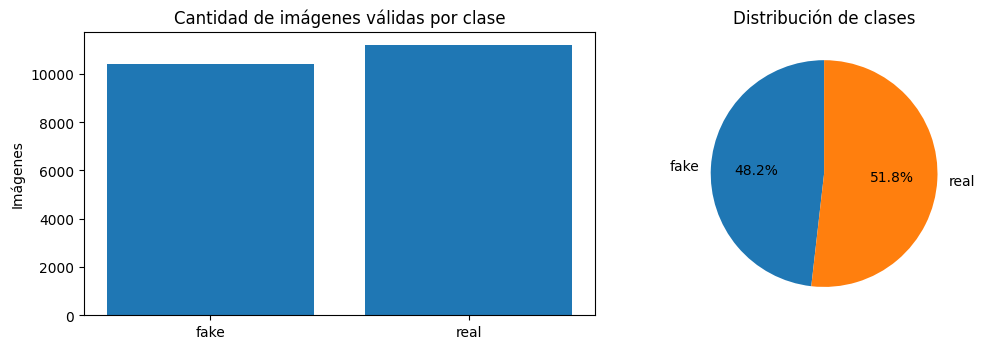

In [ ]:
cuentas = registro['class'].value_counts().reindex(CLASES)
porcentajes = (100*cuentas/cuentas.sum()).round(2)
print(pd.DataFrame({'imagenes': cuentas, 'porcentaje_%': porcentajes}))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(CLASES, cuentas.values)
axes[0].set_title('Cantidad de imágenes válidas por clase')
axes[0].set_ylabel('Imágenes')
axes[1].pie(cuentas.values, labels=CLASES, autopct='%.1f%%', startangle=90)
axes[1].set_title('Distribución de clases')
plt.tight_layout(); plt.show()

Los resultados muestran que el dataset está compuesto por un 51,81 % de imágenes reales y un 48,19 % de imágenes falsas, por lo que existe una distribución relativamente equilibrada entre ambas clases, lo que es favorable para los siguientes pasos.



### 1.3 División estratificada y agrupada: 70 / 15 / 15

La partición se realiza **por grupo de pHash idéntico**, y estratificamos (buscamos mantener la misma proporción de imágenes fake y real en los tres conjuntos) las etiquetas de esos grupos. Así, un grupo de imágenes con el mismo hash perceptual no puede aparecer tanto en entrenamiento como en validación o prueba. Por contener grupos de varios tamaños, los porcentajes exactos de imágenes pueden diferir ligeramente de 70/15/15.

Además, la división se realiza aleatoriamente mediante `train_test_split`, utilizando la semilla **2026** para obtener resultados reproducibles, manteniendo las proporciones de `fake` y `real` y agrupando las imágenes con el mismo pHash.



In [ ]:
# Formamos una fila por grupo perceptual, con etiqueta única ya validada.
gr = registro.groupby('phash').agg(clase=('class', 'first'), cantidad=('path', 'size')).reset_index()
assert gr['clase'].value_counts().min() >= 7, 'Muy pocos grupos por clase para separar en 70/15/15.'

# 1) Apartar 30% de grupos: validación y prueba.
gr_train, gr_resto = train_test_split(gr, test_size=0.30, random_state=SEED, stratify=gr['clase'])
# 2) Mitad de ese 30% a cada conjunto.
gr_val, gr_test = train_test_split(gr_resto, test_size=0.50, random_state=SEED, stratify=gr_resto['clase'])
asignacion = {str(ph): split for split, grupos in [('train',gr_train),('val',gr_val),('test',gr_test)]
                                  for ph in grupos['phash']}
registro['split'] = registro['phash'].map(asignacion)
assert registro['split'].notna().all()
assert registro.groupby('phash')['split'].nunique().max() == 1
assert registro.groupby('sha256')['split'].nunique().max() == 1

particion = pd.crosstab(registro['split'], registro['class']).reindex(index=['train','val','test'], columns=CLASES, fill_value=0)
particion['Total'] = particion.sum(axis=1)
particion['% del total'] = (100*particion['Total']/len(registro)).round(2)
print('TABLA REAL DE PARTICIÓN:')
display(particion)
print('Proporciones internas:')
display(pd.crosstab(registro['split'],registro['class'],normalize='index').round(3))
registro.to_csv(RUTA_RESULTADOS/'manifest_division.csv', index=False)
particion.to_csv(RUTA_RESULTADOS/'resumen_division.csv')

# No hay fotos compartidas entre conjuntos por su pHash.
for a,b in [('train','val'),('train','test'),('val','test')]:
    A=set(registro.loc[registro.split==a, 'phash']); B=set(registro.loc[registro.split==b,'phash'])
    assert not (A&B), f'Fuga entre {a} y {b}'
print('Sin fugas detectadas por hash exacto ni por pHash idéntico.')

TABLA REAL DE PARTICIÓN:


class,fake,real,Total,% del total
split,,,,
train,7278,7820,15098,69.97
val,1561,1680,3241,15.02
test,1560,1678,3238,15.01


Proporciones internas:


class,fake,real
split,,
test,0.482,0.518
train,0.482,0.518
val,0.482,0.518


Sin fugas detectadas por hash exacto ni por pHash idéntico.


Las 21.577 imágenes se dividieron en 15.098 para entrenamiento (69,97 %), 3.241 para validación (15,02 %) y 3.238 para prueba (15,01 %), cumpliendo prácticamente con la distribución propuesta de 70/15/15.

Con ello, la proporción de imágenes fake y real se mantuvo en los tres conjuntos, con aproximadamente un 48,2 % y un 51,8 %, respectivamente.

Además, se verificó que no existieran imágenes compartidas entre los conjuntos según sus hashes exactos o perceptuales idénticos. Por lo que de esta manera, utilizaremos el conjunto de entrenamiento para ajustar los modelos, el de validación para seleccionar la mejor configuración y el de prueba para evaluar su desempeño final.

## 2. Una imagen es una planilla de números

Una imagen digital se representa mediante un tensor de altura × ancho × canales. En RGB, cada píxel contiene tres valores (rojo, verde y azul) entre 0 y 255. Por ello, si realizamos los cálculos, una imagen de **224 × 224 × 3** contiene **150.528 valores numéricos**.

Teniendo en cuenta lo anterior, inspeccionamos imágenes originales de cada categoría para conocer su aspecto y detectar patrones evidentes de composición, tamaño o marcas de agua que podrían inducir **atajos espurios** (*shortcuts*): el modelo podría aprender a clasificar por bordes o compresión (como que las imágenes con menos calidad son las falsas), no por autenticidad.

A continuación, revisaremos algunas imágenes de las categorías `fake` y `real` para observar sus características y posibles diferencias de calidad, tamaño o composición. Esto permitirá identificar aspectos que podrían confundir al modelo durante el entrenamiento.

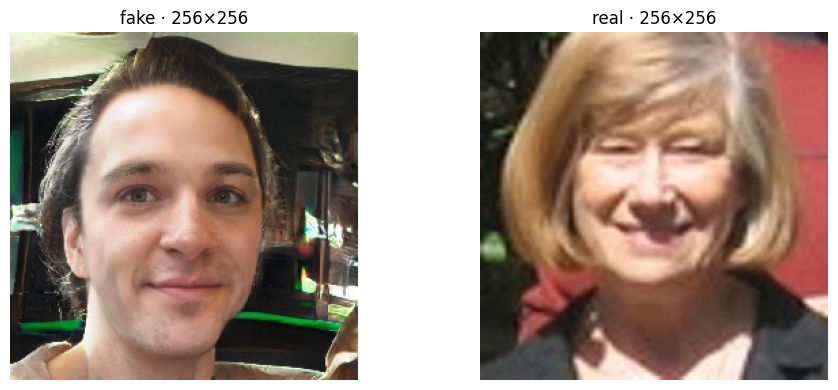

Tensor RGB original: (256, 256, 3) | tipo: uint8
Píxel [0,0]: [240, 247, 229] | total de números: 196608


In [ ]:
ejemplo_a = registro.loc[registro['class']=='fake', 'path'].iloc[0]
ejemplo_b = registro.loc[registro['class']=='real', 'path'].iloc[0]
fig, axes = plt.subplots(1,2,figsize=(10,4))
for ax, path, label in zip(axes,[ejemplo_a,ejemplo_b],CLASES):
    with Image.open(path) as pic:
        img = ImageOps.exif_transpose(pic).convert('RGB')
    ax.imshow(img); ax.axis('off'); ax.set_title(f'{label} · {img.width}×{img.height}')
plt.tight_layout();plt.show()
with Image.open(ejemplo_a) as im:
    x = np.asarray(ImageOps.exif_transpose(im).convert('RGB'))
print('Tensor RGB original:', x.shape, '| tipo:', x.dtype)
print('Píxel [0,0]:',x[0,0].tolist(), '| total de números:', x.size)

Cabe resaltar que el redimensionamiento puede eliminar artefactos finos, lo cual constituye una limitación importante para detectar contenido generado mediante IA.

## 3. Cargar imágenes como tensores

En esta etapa, utilizamos Dataset y DataLoader de PyTorch para cargar las imágenes y convertirlas en datos numéricos que los modelos puedan procesar. Además, asignamos un valor a cada categoría: fake = 0 y real = 1.

Durante el entrenamiento, aplicamos pequeñas modificaciones aleatorias a las imágenes, como giros, volteos y cambios de brillo, para ayudar a los modelos a reconocer diferentes características y evitar que memoricen las imágenes (estas modificaciones no se aplican aleatoriamente en validación ni en prueba, para evaluar los resultados de manera consistente)

Finalmente, ambos modelos utilizan las mismas imágenes para permitir una comparación justa, cada uno genera una puntuación para la categoría real, a partir de la cual se calcula también la puntuación de fake.

In [ ]:
class FotosDataset(Dataset):
    def __init__(self, frame, transform=None):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform
    def __len__(self): return len(self.frame)
    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row['path']) as im:
            image = ImageOps.exif_transpose(im).convert('RGB')
        if self.transform is not None: image = self.transform(image)
        return image, torch.tensor(float(row['class']=='real'),dtype=torch.float32)

frames = {s: registro.loc[registro['split']==s].reset_index(drop=True) for s in ['train','val','test']}

def transformar(normaliza_media, normaliza_std, train=False):
    pasos = [transforms.Resize((IMG_SIZE, IMG_SIZE))]
    if train:
        # Conservadoras: evitar distorsionar demasiado artefactos de generación.
        pasos += [transforms.RandomHorizontalFlip(p=0.5),
                  transforms.RandomRotation(degrees=5),
                  transforms.ColorJitter(brightness=0.08, contrast=0.08)]
    pasos += [transforms.ToTensor(), transforms.Normalize(normaliza_media,normaliza_std)]
    return transforms.Compose(pasos)

def crear_loaders(media, std):
    loaders={}
    for split in ['train','val','test']:
        ds=FotosDataset(frames[split], transformar(media,std,train=(split=='train')))
        gen=torch.Generator().manual_seed(SEED)
        loaders[split] = DataLoader(ds, batch_size=LOTE, shuffle=(split=='train'),
                                    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type=='cuda'),
                                    generator=gen)
    return loaders

print({s: len(frames[s]) for s in frames})

{'train': 15098, 'val': 3241, 'test': 3238}


Además, todas las imágenes se ajustan a un tamaño de **224 × 224 píxeles** y se normalizan según los requisitos de cada modelo preentrenado, para que puedan procesarlas correctamente.

Las imágenes se cargan en grupos llamados lotes (*batches*), lo que permite entrenar sin procesar todo el dataset al mismo tiempo. Durante el entrenamiento, estos lotes se forman mezclando aleatoriamente las imágenes, utilizando la semilla **2026** para favorecer la reproducibilidad.

Finalmente, se confirma que los conjuntos contienen 15.098 imágenes de entrenamiento, 3.241 de validación y 3.238 de prueba.

## 4. Construir clasificadores con modelos preentrenados

| Componente | Qué hace |
|---|---|
| *Backbone* EfficientNet-B0 / ResNet-50 | Reutiliza filtros aprendidos previamente en ImageNet. |
| Cabeza de clasificación (`num_classes=1`) | Aprende una decisión específica entre `fake` y `real`. |
| Congelamiento inicial | Entrena primero la nueva cabeza, reduciendo el riesgo de sobreajuste. |
| Ajuste fino opcional | Descongela el bloque superior con una tasa de aprendizaje muy baja. |
| `BCEWithLogitsLoss` | Penaliza predicciones erróneas de una etiqueta binaria. |

En esta etapa, utilizamos **EfficientNet-B0 y ResNet-50**, dos modelos previamente entrenados con grandes cantidades de imágenes. Esto permite aprovechar sus conocimientos anteriores y adaptarlos para distinguir imágenes `fake` y `real`, mediante una técnica llamada *transfer learning*.

Cada modelo tiene dos partes principales: el **backbone**, encargado de reconocer características como formas y texturas, y la **cabeza clasificadora**, que utiliza esas características para decidir a qué categoría pertenece la imagen.

El entrenamiento comienza manteniendo congelado el backbone, de manera que solo se entrene la cabeza clasificadora. Posteriormente, se realiza un ajuste fino, que permite modificar algunas de las últimas capas para mejorar su adaptación a nuestro dataset.

Para evaluar ambos modelos de manera justa, se utilizan los mismos conjuntos de imágenes y métricas. El mejor modelo se selecciona según los resultados de validación y posteriormente se evalúa en el conjunto de prueba.

Finalmente, se utiliza la función de pérdida `BCEWithLogitsLoss`, que permite medir los errores durante el entrenamiento y ayudar al modelo a mejorar sus predicciones.

In [ ]:
ARQUITECTURAS = {'EfficientNet-B0': 'efficientnet_b0', 'ResNet-50': 'resnet50'}

def construir_modelo(architecture):
    m = timm.create_model(architecture, pretrained=True, num_classes=1)
    cfg = timm.data.resolve_model_data_config(m)
    media, std = list(cfg['mean']), list(cfg['std'])
    # Primera fase: solo aprende la cabeza binaria.
    for p in m.parameters(): p.requires_grad = False
    for p in m.get_classifier().parameters(): p.requires_grad = True
    return m.to(DEVICE), media, std

def descongelar_final(modelo, architecture):
    # Congelamos de nuevo todo salvo la cabeza y el último bloque del backbone.
    for p in modelo.parameters(): p.requires_grad = False
    for p in modelo.get_classifier().parameters(): p.requires_grad = True
    if architecture == 'efficientnet_b0':
        bloques = [modelo.blocks[-1], modelo.conv_head, modelo.bn2]
    elif architecture == 'resnet50':
        bloques = [modelo.layer4]
    else: raise ValueError(architecture)
    for bloque in bloques:
        for p in bloque.parameters(): p.requires_grad = True

print('Comparación:', ARQUITECTURAS)

Comparación: {'EfficientNet-B0': 'efficientnet_b0', 'ResNet-50': 'resnet50'}


Seleccionamos **EfficientNet-B0 y ResNet-50** porque ambos son modelos convolucionales preentrenados, estudiados durante el módulo, que permiten aplicar *transfer learning* para adaptar sus conocimientos al problema de clasificación de imágenes reales y generadas por inteligencia artificial.

Nuestra elección se fundamenta en el árbol de decisión presentado en clases, que recomienda aplicar *fine-tuning* cuando se dispone de imágenes etiquetadas y más de 300 imágenes por clase.

La principal razón para comparar ambos modelos es que **cumplen la misma función, pero presentan diferentes arquitecturas y costos computacionales**.

Por un lado, **EfficientNet-B0** es un modelo más liviano, con aproximadamente 5,3 millones de parámetros, diseñado para lograr buenos resultados utilizando menos recursos computacionales.

Por otro lado, **ResNet-50** es un modelo más pesado, con aproximadamente 25,6 millones de parámetros, que utiliza una arquitectura residual profunda para aprender características visuales complejas.

De esta manera, buscamos **evaluar si un modelo más liviano puede alcanzar una precisión comparable a uno de mayor tamaño**, o si el uso de una arquitectura más pesada se justifica por una mejora en la capacidad de distinguir imágenes reales de imágenes generadas mediante inteligencia artificial.

La selección final se realiza mediante la comparación de sus métricas de validación, considerando especialmente los errores más relevantes para nuestro problema.

## 5. Entrenar

Se harán hasta **6 épocas de entrenamiento de cabeza** y, si está activado, **3 épocas de ajuste fino** del bloque final.

Además, en esta etapa entrenamos **EfficientNet-B0 y ResNet-50** utilizando las imágenes preparadas anteriormente. Durante el entrenamiento, cada modelo realiza predicciones, compara sus resultados con las categorías correctas (`fake` y `real`) y ajusta sus parámetros para reducir los errores.

Para medir estos errores, utilizamos la función de pérdida `BCEWithLogitsLoss` y el optimizador `AdamW`, que permite actualizar los parámetros del modelo. Además, consideramos la pequeña diferencia en la cantidad de imágenes de ambas categorías mediante `pos_weight`, evitando que una clase tenga una influencia desproporcionada en el aprendizaje.

Al finalizar cada época, evaluamos el desempeño utilizando las imágenes de validación y registramos la pérdida (*loss*) y el porcentaje de clasificaciones correctas (*accuracy*). De esta manera, podemos observar cómo evoluciona el aprendizaje de ambos modelos.

Finalmente, **guardamos la versión que obtiene la menor pérdida de validación** y utilizamos *early stopping* para detener anticipadamente cada etapa si no se observan mejoras durante tres épocas consecutivas. El conjunto de prueba se mantiene reservado para la evaluación final.

In [ ]:
def una_epoca(model, loader, criterion, optimizer=None):
    entrenando = optimizer is not None
    model.train(entrenando)
    # Los BatchNorm preentrenados permanecen en evaluación: no alteramos sus
    # estadísticas acumuladas con muestras del dataset pequeño.
    if entrenando:
        for modulo in model.modules():
            if isinstance(modulo, nn.modules.batchnorm._BatchNorm):
                modulo.eval()
    running, etiquetas, probs = 0., [], []
    for imgs, y in loader:
        imgs=imgs.to(DEVICE, non_blocking=True)
        y=y.to(DEVICE, non_blocking=True)
        if entrenando: optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(entrenando):
            logits=model(imgs).flatten()
            loss=criterion(logits,y)
            if entrenando: loss.backward();optimizer.step()
        running += loss.item()*len(y)
        etiquetas.extend(y.detach().cpu().numpy().astype(int).tolist())
        probs.extend(torch.sigmoid(logits.detach()).cpu().numpy().tolist())
    etiquetas=np.asarray(etiquetas)
    probs=np.asarray(probs)
    return {'loss': running/len(etiquetas),
            'accuracy':accuracy_score(etiquetas,probs>=0.5),
            'balanced_accuracy':balanced_accuracy_score(etiquetas,probs>=0.5)}

n_fake = int((frames['train']['class']=='fake').sum())
n_real = int((frames['train']['class']=='real').sum())
pos_weight = torch.tensor([n_fake/max(n_real,1)],dtype=torch.float32,device=DEVICE)
print('Train fake:',n_fake,'train real:',n_real,'pos_weight clase real:',pos_weight.item())

def entrenar_modelo(nombre, arquitectura):
    torch.manual_seed(SEED)    # Inicio consistente por modelo.
    modelo, media, std = construir_modelo(arquitectura)
    loaders=crear_loaders(media,std)
    criterion=nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    mejor_loss=float('inf'); historial=[]
    checkpoint=RUTA_RESULTADOS / f'{arquitectura}_mejor.pth'

    def fase(nombre_fase, epocas, lr):
        nonlocal mejor_loss
        optim=torch.optim.AdamW((p for p in modelo.parameters() if p.requires_grad),lr=lr,weight_decay=1e-4)
        sin_mejora=0
        for epoca in range(1,epocas+1):
            tr=una_epoca(modelo,loaders['train'],criterion,optimizer=optim)
            va=una_epoca(modelo,loaders['val'],criterion)
            historial.append({'fase':nombre_fase,'epoca':len(historial)+1,
                              'train_loss':tr['loss'],'val_loss':va['loss'],
                              'train_accuracy':tr['accuracy'],'val_accuracy':va['accuracy']})
            print(f'{nombre}: {nombre_fase} ep {epoca}/{epocas} | '
                  f'train loss={tr["loss"]:.4f} | val loss={va["loss"]:.4f} | val acc={va["accuracy"]:.3f}')
            if va['loss'] < mejor_loss-1e-4:
                mejor_loss=va['loss'];sin_mejora=0
                torch.save(modelo.state_dict(),checkpoint)
            else: sin_mejora += 1
            if sin_mejora >= 3:
                print('Early stopping de la fase:', nombre_fase);break

    fase('Cabeza',EPOCAS_CABEZA,1e-3)
    if AJUSTE_FINO:
        # La segunda fase continúa desde el mejor punto de la primera.
        modelo.load_state_dict(torch.load(checkpoint,map_location=DEVICE,weights_only=True))
        descongelar_final(modelo,arquitectura)
        fase('Fine-tuning',EPOCAS_AJUSTE,1e-5)
    modelo.load_state_dict(torch.load(checkpoint,map_location=DEVICE,weights_only=True))
    modelo.eval()
    return {'name':nombre,'architecture':arquitectura,'model':modelo,'loaders':loaders,
            'mean':media,'std':std,'history':pd.DataFrame(historial),'checkpoint':checkpoint}

experimentos = {}
for nombre, arquitectura in ARQUITECTURAS.items():
    print('\n'+'='*15,nombre,'='*15)
    experimentos[nombre]=entrenar_modelo(nombre,arquitectura)
print('Entrenamiento concluido. Checkpoints guardados en:',RUTA_RESULTADOS)

Train fake: 7278 train real: 7820 pos_weight clase real: 0.9306905269622803

=============== EfficientNet-B0 ===============
EfficientNet-B0: Cabeza ep 1/6 | train loss=0.8696 | val loss=0.3748 | val acc=0.891
EfficientNet-B0: Cabeza ep 2/6 | train loss=0.3000 | val loss=0.2404 | val acc=0.928
EfficientNet-B0: Cabeza ep 3/6 | train loss=0.2283 | val loss=0.1877 | val acc=0.944
EfficientNet-B0: Cabeza ep 4/6 | train loss=0.1827 | val loss=0.1633 | val acc=0.952
EfficientNet-B0: Cabeza ep 5/6 | train loss=0.1609 | val loss=0.1463 | val acc=0.959
EfficientNet-B0: Cabeza ep 6/6 | train loss=0.1421 | val loss=0.1352 | val acc=0.959
EfficientNet-B0: Fine-tuning ep 1/3 | train loss=0.1070 | val loss=0.0899 | val acc=0.974
EfficientNet-B0: Fine-tuning ep 2/3 | train loss=0.0646 | val loss=0.0734 | val acc=0.977
EfficientNet-B0: Fine-tuning ep 3/3 | train loss=0.0464 | val loss=0.0586 | val acc=0.981

=============== ResNet-50 ===============
ResNet-50: Cabeza ep 1/6 | train loss=0.2322 | val l

### Resultados del entrenamiento

Ambos modelos completaron las 6 épocas de entrenamiento inicial y las 3 épocas de ajuste fino, mostrando mejoras en sus resultados.

**EfficientNet-B0** alcanzó un accuracy de validación de **98,1 %**, con una pérdida de **0,0586**. Por su parte, **ResNet-50** obtuvo un accuracy de **98,8 %**, con una pérdida de **0,0387**.

En ambos casos, el ajuste fino permitió mejorar el desempeño respecto al entrenamiento inicial de la cabeza clasificadora. Sin embargo, ResNet-50 presentó mejores resultados de validación, tanto en accuracy como en pérdida.

Estos resultados sugieren que ResNet-50 podría ser la mejor alternativa para nuestro problema, aunque todavía debemos revisar las métricas de clasificación y el conjunto de prueba antes de establecer conclusiones sobre su desempeño final.

## 6. Curvas de aprendizaje

En esta etapa, analizamos las curvas de aprendizaje de **EfficientNet-B0 y ResNet-50**, comparando la pérdida (*loss*) y el porcentaje de clasificaciones correctas (*accuracy*) durante las nueve épocas de entrenamiento.

Esto permite observar si los modelos mejoran progresivamente y detectar posibles problemas de **sobreajuste (*overfitting*)**, cuando el modelo obtiene buenos resultados en entrenamiento, pero empeora en validación, o **subajuste (*underfitting*)**, cuando no logra aprender adecuadamente los patrones de las imágenes.

Para un aprendizaje adecuado, esperamos que la pérdida disminuya y el accuracy aumente, manteniendo resultados similares entre entrenamiento y validación.

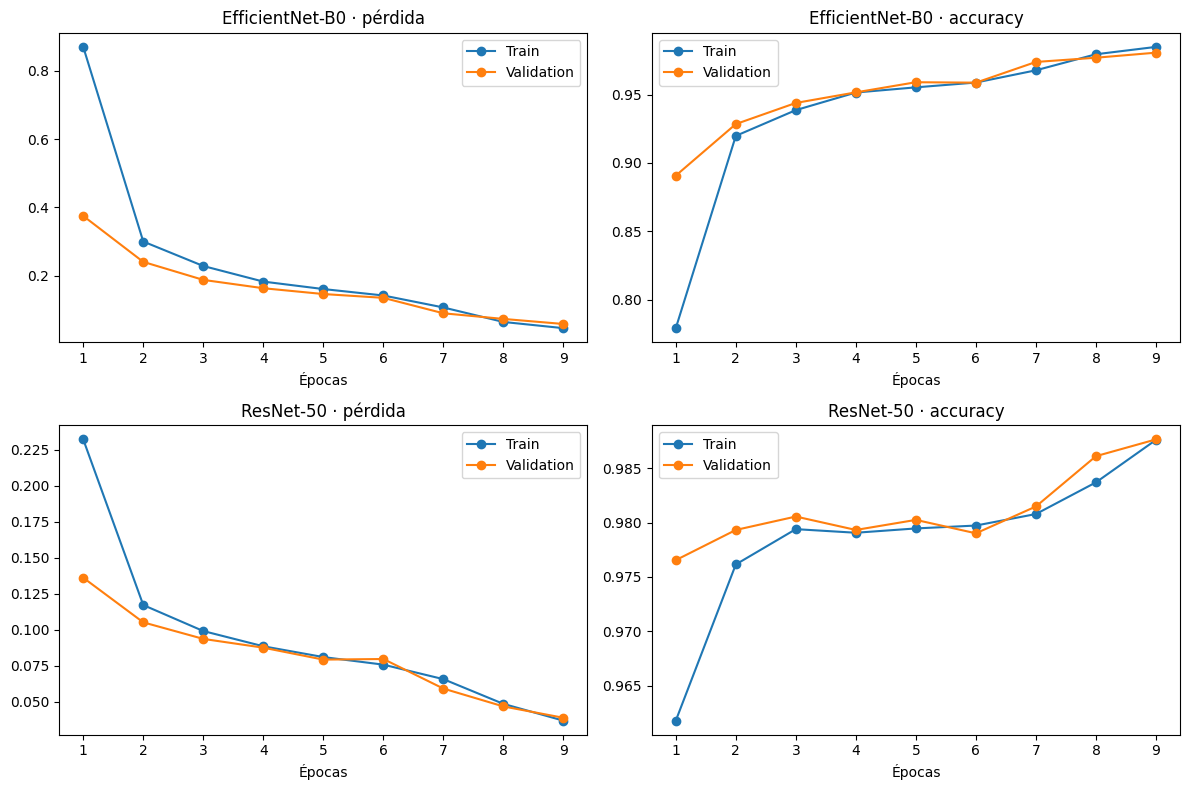

In [ ]:
fig, axes = plt.subplots(2,2,figsize=(12,8))
for i,(nombre, exp) in enumerate(experimentos.items()):
    h=exp['history']
    axes[i,0].plot(h['epoca'],h['train_loss'],marker='o',label='Train')
    axes[i,0].plot(h['epoca'],h['val_loss'],marker='o',label='Validation')
    axes[i,0].set_title(f'{nombre} · pérdida');axes[i,0].legend();axes[i,0].set_xlabel('Épocas')
    axes[i,1].plot(h['epoca'],h['train_accuracy'],marker='o',label='Train')
    axes[i,1].plot(h['epoca'],h['val_accuracy'],marker='o',label='Validation')
    axes[i,1].set_title(f'{nombre} · accuracy');axes[i,1].legend();axes[i,1].set_xlabel('Épocas')
plt.tight_layout();plt.savefig(RUTA_RESULTADOS/'curvas_aprendizaje.png',dpi=150);plt.show()

### Interpretación de las curvas

En ambos modelos, la pérdida de entrenamiento y validación disminuye de forma sostenida, mientras que el accuracy aumenta a lo largo de las épocas. Además, las curvas de entrenamiento y validación se mantienen cercanas, sin una divergencia importante.

Por lo tanto, **no se observa evidencia clara de sobreajuste** en ninguno de los dos modelos. Ambos muestran un aprendizaje estable, aunque **ResNet-50** presenta un desempeño ligeramente mejor y más consistente en validación.

## 7. Evaluación, matrices de confusión y comparación de modelos

### 7.1 Ajustar el umbral únicamente en validación

Dado que la sigmoide entrega **P(real)**, la regla es:

- `P(real) >= umbral` → `real`.
- `P(real) < umbral` → `fake`.

En esta etapa, buscamos determinar qué puntuación debe alcanzar una imagen para ser clasificada como `real` o `fake`. Aunque normalmente se utiliza un umbral de 0,5, este puede ajustarse según las características y los objetivos del problema.

En nuestro caso, buscamos **reducir el riesgo de clasificar imágenes generadas o manipuladas mediante inteligencia artificial como reales**, ya que este tipo de error podría generar una confianza equivocada en su autenticidad.

Para ello, evaluamos diferentes umbrales utilizando únicamente las imágenes de validación y seleccionamos el que obtiene el mayor **F2-score de la clase `fake`**, métrica que prioriza la detección de imágenes falsas. En caso de empate, consideramos la *balanced accuracy*.

Finalmente, comparamos los resultados de **EfficientNet-B0 y ResNet-50** para seleccionar el modelo más adecuado, reservando las imágenes de prueba para evaluar posteriormente su desempeño final. Por cierto, un F2 elevado no sustituye la evaluación del costo de esas falsas alarmas.

In [ ]:
@torch.inference_mode()
def inferir(model, loader):
    model.eval(); etiquetas=[]; probabilidades=[]
    for x,y in loader:
        logits=model(x.to(DEVICE)).flatten()
        probabilidades.extend(torch.sigmoid(logits).cpu().numpy().tolist())
        etiquetas.extend(y.numpy().astype(int).tolist())
    return np.asarray(etiquetas,dtype=int), np.asarray(probabilidades,dtype=float)

def obtener_metricas(y,p_real,umbral):
    pred=(p_real>=umbral).astype(int)
    return {'accuracy':float(accuracy_score(y,pred)),
            'balanced_accuracy':float(balanced_accuracy_score(y,pred)),
            'precision_fake':float(precision_score(y,pred,pos_label=0,zero_division=0)),
            'recall_fake':float(recall_score(y,pred,pos_label=0,zero_division=0)),
            'f1_fake':float(f1_score(y,pred,pos_label=0,zero_division=0)),
            'f2_fake':float(fbeta_score(y,pred,beta=2,pos_label=0,zero_division=0)),
            'precision_real':float(precision_score(y,pred,pos_label=1,zero_division=0)),
            'recall_real':float(recall_score(y,pred,pos_label=1,zero_division=0))}

resumen_val=[]
for nombre, exp in experimentos.items():
    y_val, p_val=inferir(exp['model'],exp['loaders']['val'])
    umbrales=np.linspace(0.2,0.8,31)
    # F2_fake y balanced_accuracy como desempate.
    mejor_umbral=max(umbrales,key=lambda u:(obtener_metricas(y_val,p_val,u)['f2_fake'],
                                          obtener_metricas(y_val,p_val,u)['balanced_accuracy'],
                                          -abs(u-0.5)))
    exp['threshold']=float(mejor_umbral)
    exp['val_true'],exp['val_probs']=y_val,p_val
    exp['val_metrics']=obtener_metricas(y_val,p_val,exp['threshold'])
    resumen_val.append({'Modelo':nombre,'Umbral_P(real)':exp['threshold'],**exp['val_metrics']})
tabla_val=pd.DataFrame(resumen_val).sort_values(['f2_fake','balanced_accuracy'],ascending=False)
display(tabla_val.round(4))
tabla_val.to_csv(RUTA_RESULTADOS/'comparacion_validacion.csv',index=False)

# Se decide el modelo ganador CON VALIDACIÓN, antes de evaluar test.
ganador=tabla_val.iloc[0]['Modelo']
print('Modelo elegido por F2_fake (validación):',ganador)
print('Umbral seleccionado:',experimentos[ganador]['threshold'])

,Modelo,Umbral_P(real),accuracy,balanced_accuracy,precision_fake,recall_fake,f1_fake,f2_fake,precision_real,recall_real
1,ResNet-50,0.76,0.9867,0.9870,0.9780,0.9949,0.9863,0.9914,0.9952,0.9792
0,EfficientNet-B0,0.72,0.9790,0.9795,0.9651,0.9923,0.9785,0.9867,0.9927,0.9667


Modelo elegido por F2_fake (validación): ResNet-50
Umbral seleccionado: 0.76


### Resultados de validación y selección del modelo

Se evaluaron ambos modelos utilizando el conjunto de validación, ajustando el umbral de clasificación para priorizar la detección de imágenes `fake`.

**ResNet-50 obtuvo un F2-score de 99,14 %**, superando el 98,67 % de EfficientNet-B0. También presentó mejores resultados de accuracy y recall para la clase `fake`.

Por lo tanto, seleccionamos **ResNet-50 con un umbral de 0,76**, ya que ofrece el mejor desempeño de validación según el criterio definido. Esto significa que una imagen deberá obtener una puntuación de al menos 0,76 para la clase `real` para ser clasificada como tal.

Esta decisión busca reducir el riesgo de clasificar imágenes falsas como auténticas. Sin embargo, todavía debemos comprobar su desempeño en el conjunto de prueba, que no se ha utilizado para seleccionar el modelo.

Para un mayor entendimiento de los resultados, se muestra la tabla a continuación del modelo ResNet-50.


| Métrica | Resultado | Interpretación |
|---|---|---|
| **Accuracy** | 98,67 % | De todas las imágenes de validación, el 98,67 % fue clasificado correctamente. |
| **Balanced accuracy** | 98,70 % | Promedio del recall de ambas categorías. Permite evaluar el desempeño considerando ambas clases por igual. |
| **Precision fake** | 97,80 % | De todas las imágenes que el modelo clasificó como `fake`, el 97,80 % realmente pertenecía a esa categoría. |
| **Recall fake** | 99,49 % | De todas las imágenes que realmente eran `fake`, el modelo identificó correctamente el 99,49 %. |
| **F1 fake** | 98,63 % | Resume el equilibrio entre precision y recall de la categoría `fake`. |
| **F2 fake** | 99,14 % | Similar al F1, pero da mayor importancia al recall de `fake`. |
| **Precision real** | 99,52 % | De todas las imágenes clasificadas como `real`, el 99,52 % realmente era `real`. |
| **Recall real** | 97,92 % | De todas las imágenes que realmente eran `real`, el modelo identificó correctamente el 97,92 %. |


### 7.2 Evaluación final independiente en prueba

Solo ahora usamos el subconjunto de prueba. Ambos modelos son evaluados sobre exactamente las mismas imágenes y con el **mismo conjunto de métricas**: accuracy, balanced accuracy, precision `fake`, recall `fake`, F1 y F2. El umbral fue fijado previamente con validación y **no se ajusta con los resultados del test**.

Matriz de confusión con orden de filas y columnas `['fake','real']`:

| Real / Predicción | `fake` | `real` |
|---|---|---|
| **fake** | Correctamente detectada | **Error más costoso:** `fake` aceptada como `real` |
| **real** | Falsa alarma | Correctamente detectada |

No debemos confundir la *accuracy* del conjunto de prueba con la puntuación de una única imagen.


 EfficientNet-B0 · reporte de prueba:
              precision    recall  f1-score   support

        fake       0.97      0.99      0.98      1560
        real       0.99      0.97      0.98      1678

    accuracy                           0.98      3238
   macro avg       0.98      0.98      0.98      3238
weighted avg       0.98      0.98      0.98      3238



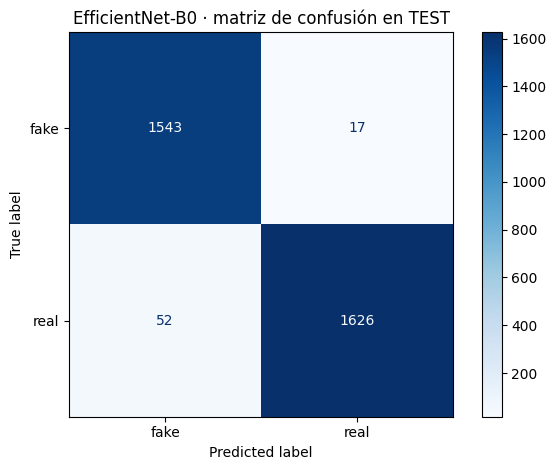


 ResNet-50 · reporte de prueba:
              precision    recall  f1-score   support

        fake       0.97      1.00      0.99      1560
        real       1.00      0.98      0.99      1678

    accuracy                           0.99      3238
   macro avg       0.99      0.99      0.99      3238
weighted avg       0.99      0.99      0.99      3238



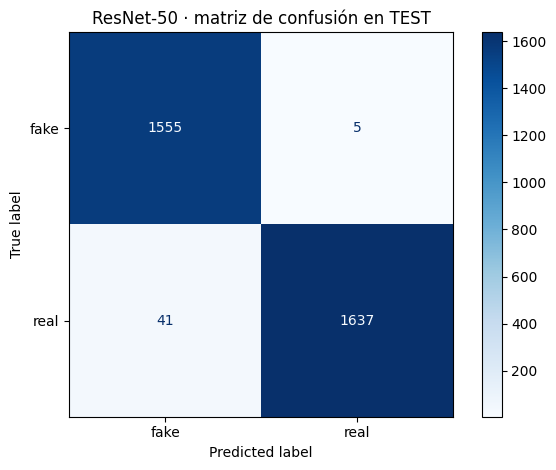

,Modelo,Umbral_P(real),accuracy,balanced_accuracy,precision_fake,recall_fake,f1_fake,f2_fake,precision_real,recall_real
0,EfficientNet-B0,0.72,0.9787,0.9791,0.9674,0.9891,0.9781,0.9847,0.9897,0.9690
1,ResNet-50,0.76,0.9858,0.9862,0.9743,0.9968,0.9854,0.9922,0.9970,0.9756


Seleccionado antes de test: ResNet-50


In [ ]:
comparacion_test=[]
for nombre,exp in experimentos.items():
    y,p=inferir(exp['model'],exp['loaders']['test'])
    exp['test_true'],exp['test_probs']=y,p
    met=obtener_metricas(y,p,exp['threshold'])
    exp['test_metrics']=met
    comparacion_test.append({'Modelo':nombre,'Umbral_P(real)':exp['threshold'],**met})
    pred=(p>=exp['threshold']).astype(int)
    print('\n',nombre,'· reporte de prueba:')
    print(classification_report(y,pred,labels=[0,1],target_names=CLASES,zero_division=0))
    cm=confusion_matrix(y,pred,labels=[0,1])
    disp=ConfusionMatrixDisplay(cm,display_labels=CLASES)
    disp.plot(cmap='Blues',values_format='d')
    plt.title(f'{nombre} · matriz de confusión en TEST');plt.tight_layout()
    plt.savefig(RUTA_RESULTADOS/f'matriz_{exp["architecture"]}.png',dpi=150)
    plt.show()
tabla_test=pd.DataFrame(comparacion_test).sort_values('Modelo')
display(tabla_test.round(4))
tabla_test.to_csv(RUTA_RESULTADOS/'comparacion_test.csv',index=False)
print('Seleccionado antes de test:',ganador)

### Interpretación de los resultados de prueba

Al evaluar ambos modelos con las **3.238 imágenes del conjunto de prueba**, ResNet-50 mantuvo un mejor desempeño que EfficientNet-B0.

**ResNet-50 alcanzó un accuracy de 98,58 % y un recall de 99,68 % para la clase `fake`**, mientras que EfficientNet-B0 obtuvo un accuracy de 97,87 % y un recall de 98,91 % para esa misma clase.

Al analizar las matrices de confusión, observamos que **EfficientNet-B0 cometió 69 errores y ResNet-50 solamente 46**. En particular, ResNet-50 clasificó incorrectamente 5 imágenes falsas como reales, frente a las 17 de EfficientNet-B0.

Este último error es especialmente importante para nuestro proyecto, ya que clasificar una imagen generada por IA como auténtica podría generar una falsa sensación de seguridad.

Por lo tanto, los resultados respaldan la elección de **ResNet-50** como modelo definitivo. Sin embargo, su buen desempeño corresponde al dataset utilizado y no garantiza la misma precisión con imágenes de otras fuentes, por lo que la aplicación deberá recomendar siempre una verificación adicional.

### 7.3 Interpretar el error más costoso

El riesgo prioritario es una imagen `fake` predicha como `real` (fila `fake`, columna `real` de la matriz). Una imagen sintética podría ser utilizada para engañar a usuarios o respaldar afirmaciones falsas. El **recall de fake** responde qué fracción de imágenes `fake` se detectó efectivamente.

El error opuesto también importa: etiquetar una fotografía auténtica como `fake` puede dañar la credibilidad de una fuente o generar falsos cuestionamientos. Por eso la app utilizará expresiones como **«posiblemente real»** o **«posiblemente generada por IA»**, incluirá un aviso de uso educativo y solicitará revisión humana cuando corresponda.


In [ ]:
exp_final=experimentos[ganador]
y=exp_final['test_true']; p=exp_final['test_probs']; u=exp_final['threshold']
pred=(p>=u).astype(int)
cm=confusion_matrix(y,pred,labels=[0,1])
print('False negatives para fake (fake → real):',int(cm[0,1]))
print('False positives para fake (real → fake):',int(cm[1,0]))
print('Recall fake:',exp_final['test_metrics']['recall_fake'])
print('Advertencia: estos resultados corresponden solo a la distribución de Deep Detect 2026.')

False negatives para fake (fake → real): 5
False positives para fake (real → fake): 41
Recall fake: 0.9967948717948718
Advertencia: estos resultados corresponden solo a la distribución de Deep Detect 2026.


## 8. ¿Dónde se equivocó? Ver errores de clasificación

Visualizamos imágenes del **test** clasificadas erróneamente para realizar un análisis cualitativo. No las usamos para reentrenar ni modificar el umbral: hacerlo contaminaría el conjunto de prueba y debilitaría la validez de las métricas reportadas.


Errores observados en el test: 46


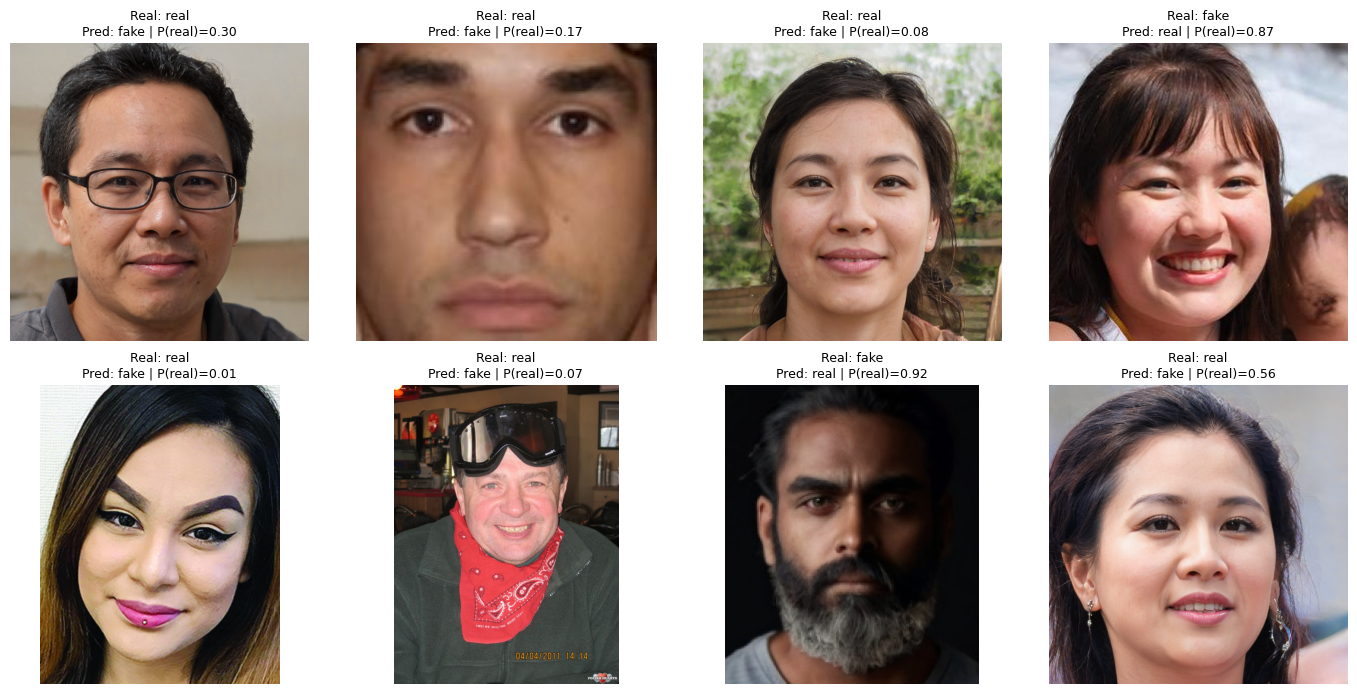

In [ ]:
idx_errores=np.flatnonzero(pred!=y)
print('Errores observados en el test:',len(idx_errores))
if len(idx_errores):
    rng=np.random.default_rng(SEED)
    elegidos=rng.choice(idx_errores,size=min(8,len(idx_errores)),replace=False)
    fig,axes=plt.subplots(2,4,figsize=(14,7))
    for ax in axes.flat: ax.axis('off')
    for ax,i in zip(axes.flat,elegidos):
        with Image.open(frames['test'].iloc[i]['path']) as im:
            ax.imshow(ImageOps.exif_transpose(im).convert('RGB'))
        ax.set_title(f'Real: {CLASES[y[i]]}\nPred: {CLASES[pred[i]]} | P(real)={p[i]:.2f}',fontsize=9)
    plt.tight_layout();plt.savefig(RUTA_RESULTADOS/'errores_ejemplo.png',dpi=150);plt.show()
else:
    print('No hay errores registrados en esta partición: no garantiza ausencia de fallos fuera del dataset.')

### Interpretación de los errores observados

Al revisar algunos errores del conjunto de prueba, se observa que varios corresponden a **rostros en primer plano**, con encuadres centrados o rasgos visuales muy limpios. En algunos casos, imágenes reales fueron clasificadas como `fake`, posiblemente porque presentan características visuales similares a las de imágenes generadas por IA, como piel uniforme e iluminación controlada.

También aparecen algunos casos de imágenes `fake` clasificadas como `real`, lo que sugiere que ciertas imágenes sintéticas resultan visualmente muy convincentes y no presentan artefactos evidentes tras el redimensionamiento.

Sin embargo, este análisis es cualitativo y se basa solo en una muestra de errores del conjunto de prueba.

## 9. ¿Qué miran los filtros? Interpretabilidad con Grad-CAM

En esta etapa, utilizamos **Grad-CAM** para visualizar qué zonas de una imagen influyen más en las predicciones del modelo seleccionado, ResNet-50.

Esta técnica genera un **mapa de calor** que permite identificar las regiones a las que el modelo da mayor importancia al clasificar una imagen como `fake` o `real`.

De esta manera, podemos comprender mejor cómo realiza sus predicciones y observar si presta atención a características relevantes de las imágenes. Sin embargo, las zonas destacadas no demuestran por sí solas que exista una manipulación, por lo que los resultados deben interpretarse con precaución.

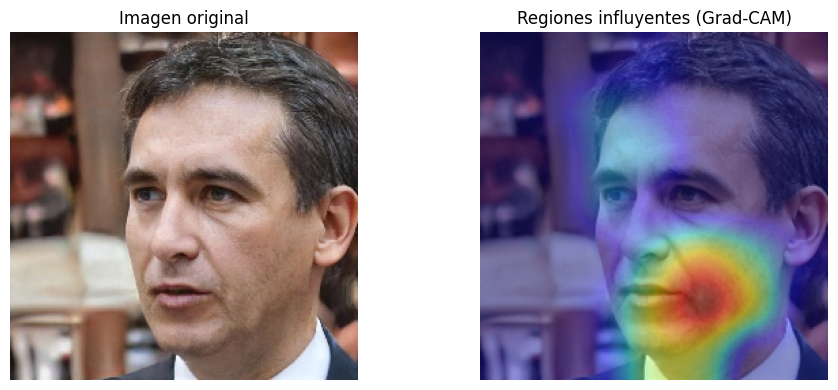

In [ ]:
def gradcam(modelo, input_tensor, clase=0):
    # clase 0 (fake): usar el negativo del logit P(real); clase 1: el logit.
    convs=[m for m in modelo.modules() if isinstance(m,nn.Conv2d)]
    assert convs, 'No se encontraron capas convolucionales'
    target=convs[-1]; capturas={}
    def forward_hook(_m,_in,out):
        capturas['activaciones']=out
        out.register_hook(lambda g: capturas.__setitem__('gradientes',g))
    handler=target.register_forward_hook(forward_hook)
    try:
        modelo.eval();modelo.zero_grad(set_to_none=True)
        logits=modelo(input_tensor.to(DEVICE)).flatten()
        score=logits[0] if clase==1 else -logits[0]
        score.backward()
        act=capturas['activaciones'].detach()[0]
        grad=capturas['gradientes'].detach()[0]
        pesos=grad.mean(dim=(1,2),keepdim=True)
        heat=torch.relu((pesos*act).sum(dim=0)).cpu().numpy()
        heat=(heat-heat.min())/(np.ptp(heat)+1e-8)
        return heat
    finally: handler.remove()

ruta_demo=frames['test'].iloc[0]['path']
with Image.open(ruta_demo) as im:
    original=ImageOps.exif_transpose(im).convert('RGB')
transf=transformar(exp_final['mean'],exp_final['std'],train=False)
x_demo=transf(original).unsqueeze(0)
clase_predicha=int(exp_final['test_probs'][0]>=exp_final['threshold'])
mapa=gradcam(exp_final['model'],x_demo,clase=clase_predicha)
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].imshow(original);axes[0].axis('off');axes[0].set_title('Imagen original')
axes[1].imshow(original.resize((IMG_SIZE,IMG_SIZE)))
axes[1].imshow(Image.fromarray(np.uint8(mapa*255)).resize((IMG_SIZE,IMG_SIZE)),alpha=.43,cmap='jet')
axes[1].axis('off');axes[1].set_title('Regiones influyentes (Grad-CAM)')
plt.tight_layout();plt.savefig(RUTA_RESULTADOS/'gradcam.png',dpi=150);plt.show()

### Interpretación de Grad-CAM

El mapa de Grad-CAM muestra una mayor activación en la zona de la **boca y la mejilla**, mientras que otras regiones presentan una influencia relativa menor.Lo que sugiere que, para esta imagen, ResNet-50 utilizó principalmente características de la parte inferior del rostro al realizar su clasificación.

Sin embargo, el mapa no permite determinar exactamente qué patrones identificó el modelo ni comprobar que correspondan a señales de manipulación. Por lo tanto, esta visualización sirve para comprender mejor su comportamiento, pero no constituye una prueba de autenticidad.

## 10. Probar con una foto nueva

Una imagen de uso personal o una fotografía externa puede subirse en Colab con `files.upload()`. El modelo debe aplicar **las mismas transformaciones de evaluación** que usó en la comparación. Reportamos siempre las dos puntuaciones, sin afirmar autenticidad demostrada.

*La aplicación de los próximos puntos tendrá su propio cargador de imágenes, por lo cual este bloque sirve como ensayo de inferencia fuera del dataset.*

In [ ]:
def predecir_pil(image, exp):
    tensor=transformar(exp['mean'],exp['std'],train=False)(image.convert('RGB')).unsqueeze(0).to(DEVICE)
    exp['model'].eval()
    with torch.inference_mode():
        p_real=float(torch.sigmoid(exp['model'](tensor).flatten()[0]).item())
    pred_clase='real' if p_real>=exp['threshold'] else 'fake'
    return {'prediccion':pred_clase,'p_fake':1-p_real,'p_real':p_real,
            'puntuacion_predicha':p_real if pred_clase=='real' else 1-p_real}

# Ejemplo automático con una foto de test (solo demostración de inferencia).
with Image.open(frames['test'].iloc[0]['path']) as im:
    salida=predecir_pil(ImageOps.exif_transpose(im),exp_final)
print(salida)

# Para subir una imagen personal desde Colab, descomentar:
# from google.colab import files
# from io import BytesIO
# subida = files.upload()
# for nombre, contenido in subida.items():
#     imagen = Image.open(BytesIO(contenido)).convert('RGB')
#     print(nombre, predecir_pil(imagen, exp_final))

{'prediccion': 'fake', 'p_fake': 0.9926838148385286, 'p_real': 0.007316185161471367, 'puntuacion_predicha': 0.9926838148385286}


Saving imagenreal.jpeg to imagenreal.jpeg


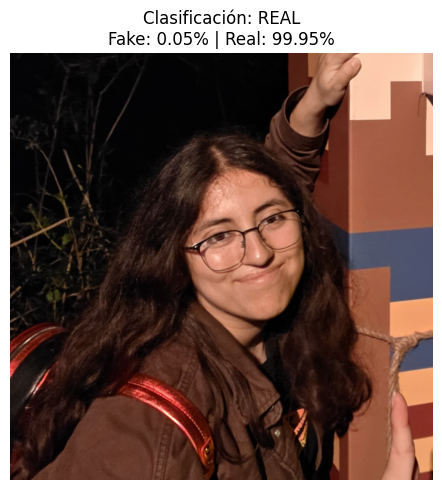

Imagen: imagenreal.jpeg
Clasificación: real
Puntuación fake: 0.05%
Puntuación real: 99.95%


In [ ]:

from google.colab import files
from io import BytesIO

# Subir una imagen externa para probar el modelo
subida = files.upload()

for nombre, contenido in subida.items():
    imagen = Image.open(BytesIO(contenido))
    imagen = ImageOps.exif_transpose(imagen).convert('RGB')

    resultado = predecir_pil(imagen, exp_final)

    # Mostrar la imagen junto con el resultado de clasificación
    plt.figure(figsize=(6, 5))
    plt.imshow(imagen)
    plt.axis('off')
    plt.title(
        f"Clasificación: {resultado['prediccion'].upper()}\n"
        f"Fake: {resultado['p_fake']:.2%} | Real: {resultado['p_real']:.2%}",
        fontsize=12
    )
    plt.tight_layout()
    plt.show()

    print('Imagen:', nombre)
    print('Clasificación:', resultado['prediccion'])
    print(f"Puntuación fake: {resultado['p_fake']:.2%}")
    print(f"Puntuación real: {resultado['p_real']:.2%}")


### Resultado de la prueba con una imagen externa

Para comprobar el funcionamiento del modelo fuera del dataset de entrenamiento, utilizamos una fotografía real de una integrante del grupo.

El modelo **ResNet-50 clasificó correctamente la imagen como `real`**, obteniendo una puntuación de **99,95 % para `real`** y **0,05 % para `fake`**. Además, la puntuación de la categoría `real` superó ampliamente el umbral de clasificación establecido en 76 %, mostrando una predicción favorable para esta imagen.



Saving imagenfake.png to imagenfake.png


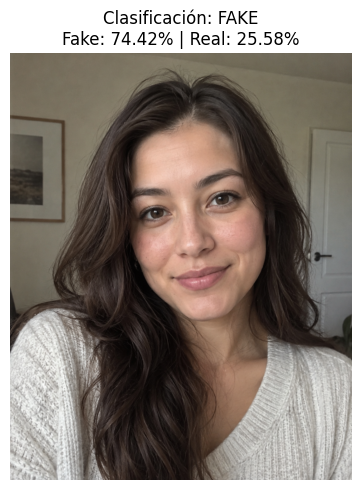

Imagen: imagenfake.png
Clasificación: fake
Puntuación fake: 74.42%
Puntuación real: 25.58%


In [ ]:

from google.colab import files
from io import BytesIO

# Subir una imagen externa para probar el modelo
subida = files.upload()

for nombre, contenido in subida.items():
    imagen = Image.open(BytesIO(contenido))
    imagen = ImageOps.exif_transpose(imagen).convert('RGB')

    resultado = predecir_pil(imagen, exp_final)

    # Mostrar la imagen junto con el resultado de clasificación
    plt.figure(figsize=(6, 5))
    plt.imshow(imagen)
    plt.axis('off')
    plt.title(
        f"Clasificación: {resultado['prediccion'].upper()}\n"
        f"Fake: {resultado['p_fake']:.2%} | Real: {resultado['p_real']:.2%}",
        fontsize=12
    )
    plt.tight_layout()
    plt.show()

    print('Imagen:', nombre)
    print('Clasificación:', resultado['prediccion'])
    print(f"Puntuación fake: {resultado['p_fake']:.2%}")
    print(f"Puntuación real: {resultado['p_real']:.2%}")


### Prueba con una imagen generada por IA

Para complementar la evaluación externa, utilizamos un retrato generado mediante **ChatGPT**, cuyo origen sintético conocemos.

El modelo ResNet-50 clasificó la imagen como `fake`, con una puntuación de **74,42 % para `fake` y 25,58 % para `real`**. Por lo tanto, la clasificación coincide con el origen de la imagen.

Este resultado es relevante porque demuestra que el modelo también logró identificar correctamente una imagen generada por IA fuera del dataset utilizado para su entrenamiento.

Sin embargo, al igual que en la prueba con la fotografía real, una sola clasificación correcta no permite garantizar que el modelo mantendrá su desempeño frente a imágenes generadas por otras herramientas o con características diferentes.

## 11. Guardar el modelo y conectarlo a la aplicación web

En esta última etapa, guardamos **ResNet-50**, seleccionado por sus resultados de validación, para utilizarlo posteriormente en nuestra aplicación web sin necesidad de volver a entrenarlo.

Para ello, exportamos tres archivos: `modelo_final.pth`, que contiene el modelo entrenado junto con los parámetros aprendidos por ResNet-50 durante el entrenamiento ; `config.json`, que guarda la configuración necesaria para cargar el modelo y clasificar correctamente las imágenes, incluyendo las clases y el umbral seleccionado. y las categorías `fake` y `real`; y `metricas.json`, que contiene los resultados obtenidos en el conjunto de prueba para mostrar el desempeño del modelo en la aplicación.

Estos archivos permitirán que la aplicación **reciba una imagen, la clasifique y muestre sus puntuaciones**, además de informar el desempeño general del modelo.


*Después de ejecutar, se copiaron los tres archivos en el repositorio GitHub para conectarlos con la aplicación desarrollada en Streamlit.*

In [ ]:
cfg_salida = {'architecture':exp_final['architecture'],'class_names':CLASES,
    'image_size':IMG_SIZE,'mean':list(exp_final['mean']),'std':list(exp_final['std']),
    'threshold_real':float(exp_final['threshold']),'seed':SEED,
    'dataset':DATASET_SLUG,'training_split':'70/15/15 por grupo pHash'}
archivo_pesos=RUTA_MODELO/'modelo_final.pth'
state_cpu=exp_final['model'].cpu().state_dict()
# ResNet-50 puede sobrepasar el límite de 100 MB de GitHub en FP32.
# Si pesa > 95 MB, exportamos pesos flotantes en FP16; al cargar, timm
# los convierte a FP32. Esto cambia mínimamente la precisión numérica.
total_bytes=sum(t.nelement()*t.element_size() for t in state_cpu.values())
reducido_fp16=(total_bytes > 95*1024*1024)
if reducido_fp16:
    state_cpu={k:(v.half() if torch.is_floating_point(v) else v)
               for k,v in state_cpu.items()}
    print('Exportación FP16 para archivo GitHub <100 MB. Verifique métricas con modelo recargado.')
torch.save({'state_dict':state_cpu},archivo_pesos)
cfg_salida['fp16_export']=reducido_fp16
exp_final['model'].to(DEVICE)
# Validar que los pesos exportados se puedan reconstruir e inferir.
modelo_verificacion=timm.create_model(exp_final['architecture'],pretrained=False,num_classes=1)
modelo_verificacion.load_state_dict(torch.load(archivo_pesos,map_location='cpu',weights_only=True)['state_dict'])
modelo_verificacion.to(DEVICE).eval()
_, prob_verificacion=inferir(modelo_verificacion,exp_final['loaders']['test'])
metricas_exportadas=obtener_metricas(exp_final['test_true'],prob_verificacion,exp_final['threshold'])
if metricas_exportadas != exp_final['test_metrics']:
    print('ATENCIÓN: la precisión de exportación modificó las predicciones de prueba.')
    print('Métricas reales del modelo EXPORTADO: ',metricas_exportadas)
exp_final['test_metrics']=metricas_exportadas
(RUTA_MODELO/'config.json').write_text(json.dumps(cfg_salida,ensure_ascii=False,indent=2),encoding='utf-8')
(RUTA_MODELO/'metricas.json').write_text(json.dumps(exp_final['test_metrics'],ensure_ascii=False,indent=2),encoding='utf-8')
print('Se exportaron:')
for p in RUTA_MODELO.iterdir(): print(p.name,round(p.stat().st_size/1024/1024,2),'MB')
# Comprimir los tres archivos para copiarlos a GitHub en el proyecto.
archivo_zip=shutil.make_archive(str(CARPETA_PROYECTO/'modelo_exportado'),'zip',root_dir=CARPETA_PROYECTO,base_dir='modelo')
print('Archivo de transferencia:',archivo_zip)
# En Colab, si se desea descargar automáticamente:
# from google.colab import files
# files.download(archivo_zip)

Se exportaron:
modelo_final.pth 89.99 MB
config.json 0.0 MB
metricas.json 0.0 MB
Archivo de transferencia: /content/DeepDetect_2026_proyecto/modelo_exportado.zip


## 12. Conclusión del entrenamiento y evaluación

En esta primera etapa, se desarrollaron y evaluaron dos modelos preentrenados, **EfficientNet-B0 y ResNet-50**, para clasificar imágenes faciales como reales o generadas o manipuladas mediante inteligencia artificial. Ambos presentaron resultados favorables, sin señales evidentes de sobreajuste. Sin embargo, **ResNet-50 obtuvo un mejor desempeño en validación, alcanzando un accuracy de 98,67 % y un F2-score de 99,14 % para la categoría `fake`**, por lo que fue seleccionado para la aplicación web. Posteriormente, en el conjunto de prueba, logró identificar correctamente aproximadamente el **99,68 % de las imágenes `fake`**, aunque clasificó incorrectamente 5 imágenes falsas como reales y 41 imágenes reales como falsas.

Estos resultados permiten concluir que **ResNet-50 presenta una alta capacidad para distinguir ambas categorías dentro del dataset utilizado**, aunque sus predicciones no garantizan la autenticidad de una imagen. Por ello, la siguiente etapa consiste en integrar el modelo en una aplicación web que permita visualizar las clasificaciones y sus puntuaciones, incorporando además **inteligencia artificial generativa para entregar recomendaciones de verificación**. De esta manera, se busca complementar el análisis del modelo con orientaciones comprensibles para el usuario, promoviendo una interpretación responsable de los resultados.

# Parte II: Desarrollo de la aplicación web DeepDetect 2026

En esta segunda parte desarrollamos una aplicación web utilizando **Streamlit**, que permite clasificar imágenes reales y generadas por inteligencia artificial mediante el modelo ResNet-50 entrenado y seleccionado en la Parte I.

La aplicación permite cargar una imagen, visualizar su clasificación y las puntuaciones de ambas clases, consultar las métricas globales del modelo y obtener recomendaciones generadas mediante la API de Gemini.

Primero desarrollamos y probamos su funcionamiento en Google Colab. Posteriormente, prepararemos los archivos necesarios para publicarla mediante GitHub y Streamlit Community Cloud.



## 13. Preparación del entorno y recuperación del modelo

Para comenzar, instalamos las librerías necesarias para ejecutar la aplicación. Luego recuperamos los archivos exportados anteriormente, que contienen los pesos del modelo, su configuración y las métricas obtenidas durante la evaluación.

In [3]:

# Instalar Streamlit para desarrollar la aplicación web
!pip install -q streamlit


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 51.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 66.7 MB/s eta 0:00:00


In [4]:
# Instalar las librerías necesarias para DeepDetect
!pip install -q timm torchvision pillow google-genai


### 13.1. Recuperación del modelo entrenado

Para utilizar ResNet-50 en la aplicación, necesitamos recuperar los archivos exportados en la Parte I:

- `modelo_final.pth`: pesos del modelo entrenado.
- `config.json`: configuración de la arquitectura, preprocesamiento y umbral de clasificación.
- `metricas.json`: resultados de evaluación obtenidos en el conjunto de prueba.

El siguiente código comprueba si estos archivos ya están disponibles. En caso contrario, permite subir el archivo ZIP exportado previamente.

In [5]:

from google.colab import files
from pathlib import Path
import zipfile

# Subir el archivo que contiene el modelo entrenado
subida = files.upload()

# Extraer los archivos del modelo
with zipfile.ZipFile("modelo_exportado.zip", "r") as zip_ref:
    zip_ref.extractall("/content")

# Comprobar que se extrajeron correctamente
carpeta_modelo = Path("/content/modelo")

print("Archivos disponibles:")
for archivo in carpeta_modelo.iterdir():
    print("-", archivo.name)


Saving modelo_exportado.zip to modelo_exportado.zip
Archivos disponibles:
- config.json
- modelo_final.pth
- metricas.json


## 14. Desarrollo de la aplicación web en Streamlit

Una vez recuperado el modelo entrenado, desarrollamos la aplicación web **DeepDetect 2026** utilizando Streamlit.

La aplicación integra ResNet-50 para clasificar las imágenes proporcionadas por el usuario y presenta los resultados mediante una interfaz visual personalizada.

Además de la clasificación, permite consultar las puntuaciones de ambas clases, visualizar las métricas obtenidas en el conjunto de prueba y solicitar recomendaciones generadas mediante Gemini.

Para desarrollar la aplicación utilizamos un archivo independiente llamado `app.py`, que contiene la interfaz, la carga del modelo, el procesamiento de imágenes y la conexión con la API de Gemini.

### 14.1. Preparación del archivo de la aplicación

A continuación, incorporamos el archivo `app.py` al entorno de Google Colab. Este archivo utiliza los pesos y la configuración del modelo recuperados en la sección anterior.

In [18]:

%%writefile /content/app.py

import os
import json
import hashlib
from pathlib import Path

import streamlit as st
import torch
import timm
from google import genai
from PIL import Image, ImageOps
from torchvision import transforms


# =========================================================
# 1. CONFIGURACIÓN GENERAL
# =========================================================

st.set_page_config(
    page_title="DeepDetect 2026",
    page_icon="🔎",
    layout="wide",
    initial_sidebar_state="collapsed",
)

CARPETA_MODELO = Path(__file__).resolve().parent / "modelo"


# =========================================================
# 2. DISEÑO VISUAL
# =========================================================

st.markdown("""
<style>
    .stApp {
        background:
            radial-gradient(
                ellipse at 85% 0%,
                rgba(47, 73, 149, 0.22),
                transparent 42%
            ),
            #0B1020;
        color: #F4F7FF;
    }

    .block-container {
        max-width: 1250px;
        padding-top: 2rem;
        padding-bottom: 3rem;
    }

    #MainMenu {visibility: hidden;}
    footer {visibility: hidden;}

    h1, h2, h3, p, label {
        color: #F4F7FF;
    }

    /* Identidad */
    .brand {
        display: flex;
        align-items: center;
        gap: 14px;
        margin-bottom: 25px;
    }

    .brand-icon {
        background: #24315C;
        border: 1px solid #4059A2;
        padding: 11px 14px;
        border-radius: 13px;
        font-size: 26px;
    }

    .brand-name {
        font-size: 28px;
        font-weight: 800;
        letter-spacing: -1px;
        color: #FFFFFF;
    }

    .brand-name span {
        color: #89AAFC;
    }

    .brand-subtitle {
        font-size: 11px;
        color: #A0B2D5;
        letter-spacing: 2px;
        margin-top: 4px;
    }

    /* Encabezado principal: propósito claro y referencia visual */
    .hero {
        background: linear-gradient(125deg, #162747 0%, #101B34 58%, #182B51 100%);
        border: 1px solid #344B77;
        border-radius: 22px;
        padding: 34px 36px;
        margin-bottom: 25px;
        box-shadow: 0 14px 38px rgba(0, 0, 0, 0.22);
        overflow: hidden;
    }

    .hero-grid {
        display: grid;
        grid-template-columns: minmax(0, 1.25fr) minmax(260px, 0.85fr);
        gap: 30px;
        align-items: center;
    }

    .eyebrow {
        color: #A5BDFF;
        font-size: 11px;
        font-weight: 750;
        letter-spacing: 1.8px;
        margin-bottom: 14px;
    }

    .hero-title {
        color: #FFFFFF;
        font-size: clamp(29px, 3.7vw, 44px);
        font-weight: 800;
        letter-spacing: -1.3px;
        line-height: 1.16;
        margin-bottom: 16px;
    }

    .hero-description {
        color: #C1CDE2;
        font-size: 15px;
        line-height: 1.7;
        margin-bottom: 20px;
        max-width: 640px;
    }

    .tag {
        display: inline-block;
        background: #233A60;
        border: 1px solid #3D5687;
        border-radius: 8px;
        padding: 7px 11px;
        color: #D7E4FF;
        font-size: 12px;
        margin-right: 7px;
        margin-bottom: 7px;
    }

    /* Gráfico ilustrativo: NO representa una detección realizada */
    .hero-visual {
        background: linear-gradient(165deg, #22385D 0%, #121E37 100%);
        border: 1px solid #46649C;
        border-radius: 20px;
        padding: 18px;
        position: relative;
        min-width: 0;
    }

    .visual-top {
        display: flex;
        justify-content: space-between;
        align-items: center;
        gap: 8px;
        color: #BCD0F5;
        font-size: 10px;
        letter-spacing: 1px;
        text-transform: uppercase;
        margin-bottom: 12px;
    }

    .visual-top strong {
        color: #9EBBFA;
        font-weight: 700;
    }

    .face-frame {
        height: 190px;
        border: 1px solid rgba(138, 171, 238, 0.35);
        border-radius: 15px;
        background:
            linear-gradient(transparent 98%, rgba(137, 170, 252, .10) 99%),
            linear-gradient(90deg, transparent 98%, rgba(137, 170, 252, .10) 99%),
            radial-gradient(ellipse at center, #2B426C 0%, #172643 67%);
        background-size: 100% 25px, 25px 100%, auto;
        display: flex;
        align-items: center;
        justify-content: center;
        position: relative;
        overflow: hidden;
    }

    .face-illustration {
        position: relative;
        width: 128px;
        height: 154px;
        display: flex;
        flex-direction: column;
        align-items: center;
        justify-content: flex-end;
    }

    .face-head {
        width: 67px;
        height: 80px;
        border-radius: 44% 44% 46% 46%;
        border: 2px solid #A9C6FF;
        background: linear-gradient(160deg, #789AD0, #415F9B);
        position: relative;
        z-index: 2;
        box-shadow: inset -9px -7px 13px rgba(9, 18, 38, .28);
    }

    .face-head::before,
    .face-head::after {
        content: "";
        position: absolute;
        top: 35px;
        height: 3px;
        width: 9px;
        border-radius: 3px;
        background: #182C50;
    }
    .face-head::before {left: 15px;}
    .face-head::after {right: 15px;}

    .face-shoulders {
        height: 57px;
        width: 121px;
        margin-top: -4px;
        border: 2px solid #A9C6FF;
        border-bottom: 0;
        border-radius: 62px 62px 0 0;
        background: linear-gradient(160deg, #587EC0, #293E68);
    }

    .frame-corner {
        position: absolute;
        width: 24px;
        height: 24px;
        border-color: #A9C6FF;
        border-style: solid;
    }
    .corner-tl {top: 13px; left: 13px; border-width: 2px 0 0 2px;}
    .corner-tr {top: 13px; right: 13px; border-width: 2px 2px 0 0;}
    .corner-bl {bottom: 13px; left: 13px; border-width: 0 0 2px 2px;}
    .corner-br {bottom: 13px; right: 13px; border-width: 0 2px 2px 0;}

    .scan-line {
        position: absolute;
        top: 49%;
        left: 10%;
        right: 10%;
        height: 2px;
        background: linear-gradient(90deg, transparent, #8CE8FF, transparent);
        box-shadow: 0 0 14px rgba(140, 232, 255, .75);
        z-index: 3;
    }

    .visual-bottom {
        display: flex;
        align-items: center;
        justify-content: space-between;
        gap: 10px;
        padding-top: 15px;
        color: #B8C8E4;
        font-size: 12px;
    }

    .visual-classes {
        display: flex;
        gap: 7px;
    }

    .visual-class {
        background: #213A5F;
        color: #E1EAFF;
        border: 1px solid #476499;
        border-radius: 7px;
        padding: 5px 9px;
        font-size: 11px;
    }

    .visual-note {
        margin-top: 10px;
        font-size: 10px;
        color: #90A7CF;
        line-height: 1.5;
    }

    /* Títulos y paneles */
    .section-heading {
        color: #F4F7FF;
        font-weight: 750;
        font-size: 19px;
        margin-top: 15px;
        margin-bottom: 12px;
    }

    .section-heading span {
        color: #89AAFC;
        font-size: 13px;
        margin-right: 8px;
        letter-spacing: 1px;
    }

    .panel {
        background: #15203A;
        border: 1px solid #293A5D;
        border-radius: 16px;
        padding: 20px;
        margin-bottom: 15px;
    }

    .panel-small {
        background: #172440;
        border: 1px solid #304775;
        border-radius: 15px;
        padding: 20px;
    }

    /* Diagnóstico */
    .diagnostic {
        background: #3B2E23;
        border: 1px solid #6D5437;
        border-radius: 13px;
        padding: 20px;
        margin-bottom: 18px;
    }

    .diagnostic.real {
        background: #17352F;
        border-color: #276B59;
    }

    .diagnostic-label {
        color: #F8C78F;
        font-size: 12px;
        letter-spacing: 1px;
        font-weight: 750;
    }

    .diagnostic.real .diagnostic-label {
        color: #85E2BE;
    }

    .diagnostic-score {
        color: #FFFFFF;
        font-size: 40px;
        font-weight: 800;
        line-height: 1.3;
        margin-top: 6px;
    }

    .diagnostic-caption {
        color: #C9B9A7;
        font-size: 12px;
    }

    .diagnostic.real .diagnostic-caption {
        color: #AAD1C5;
    }

    /* Barras de clasificación */
    .score-row {
        display: flex;
        justify-content: space-between;
        color: #DCE5F5;
        font-size: 14px;
        margin: 16px 0 7px;
    }

    .score-track {
        height: 10px;
        background: #303B55;
        border-radius: 20px;
        overflow: hidden;
    }

    .score-fill {
        height: 100%;
        border-radius: 20px;
    }

    /* Métricas */
    .metric-card {
        background: #15203A;
        border: 1px solid #293A5D;
        border-radius: 15px;
        padding: 22px;
        margin-top: 12px;
    }

    .metric-value {
        color: #FFFFFF;
        font-size: 30px;
        font-weight: 800;
    }

    .metric-label {
        color: #A7B7D3;
        font-size: 12px;
        margin-top: 5px;
    }

    .fine-print {
        color: #98AAC9;
        font-size: 12px;
        line-height: 1.6;
    }

    /* Botones */
    div.stButton > button {
        background: #5267C7;
        color: #FFFFFF;
        border: none;
        border-radius: 10px;
        font-weight: 700;
        padding: 11px 20px;
    }

    div.stButton > button:hover {
        background: #657BE3;
        color: #FFFFFF;
        border: none;
    }

    /* Cargador de imágenes */
    [data-testid="stFileUploader"] {
        background: #15203A;
        border: 1px dashed #5271AF;
        border-radius: 13px;
        padding: 14px;
    }

    [data-testid="stImage"] img {
        border-radius: 13px;
    }

    /* Respuesta generada por Gemini */
    .st-key-gemini_result {
        background: #151E35;
        border: 1px solid #6275C8 !important;
        border-radius: 18px;
        padding: 22px;
        margin-top: 14px;
        margin-bottom: 20px;
    }

    .st-key-gemini_result [data-testid="stVerticalBlock"] {
        gap: 0.55rem;
    }

    .st-key-gemini_result h3 {
        color: #DCE4FF;
        font-size: 23px;
        margin: 0;
        padding: 0;
    }

    .st-key-gemini_result p,
    .st-key-gemini_result li {
        line-height: 1.55;
    }

    /* Desplegable de información */
    [data-testid="stExpander"] {
        background: #111B33;
        border: 1px solid #293A5D;
        border-radius: 12px;
    }

    [data-testid="stExpander"] summary {
        background: #172440;
        color: #E5ECFC;
        border-radius: 10px;
    }

    /* Encabezado adaptable a dispositivos pequeños */
    @media (max-width: 900px) {
        .hero-grid { grid-template-columns: 1fr; }
        .hero-visual { max-width: 480px; width: 100%; }
    }

    /* Adaptación a pantallas pequeñas */
    @media (max-width: 700px) {
        .block-container {
            padding: 1.2rem 1rem;
        }

        .hero {
            padding: 25px 20px;
        }

        .hero-description {
            font-size: 14px;
        }

        .metric-value {
            font-size: 24px;
        }

        .st-key-gemini_result {
            padding: 15px;
        }
    }
</style>
""", unsafe_allow_html=True)


# =========================================================
# 3. CARGA DEL MODELO Y MÉTRICAS
# =========================================================

@st.cache_resource
def cargar_modelo():
    with open(
        CARPETA_MODELO / "config.json",
        encoding="utf-8"
    ) as f:
        config = json.load(f)

    modelo = timm.create_model(
        config["architecture"],
        pretrained=False,
        num_classes=1,
    )

    checkpoint = torch.load(
        CARPETA_MODELO / "modelo_final.pth",
        map_location="cpu",
        weights_only=True,
    )

    modelo.load_state_dict(checkpoint["state_dict"])
    modelo.eval()

    return modelo, config


@st.cache_data
def cargar_metricas():
    with open(
        CARPETA_MODELO / "metricas.json",
        encoding="utf-8"
    ) as f:
        return json.load(f)


modelo, config = cargar_modelo()
metricas = cargar_metricas()


def analizar_imagen(imagen):
    transformacion = transforms.Compose([
        transforms.Resize(
            (config["image_size"], config["image_size"])
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=config["mean"],
            std=config["std"],
        ),
    ])

    tensor = transformacion(imagen).unsqueeze(0)

    with torch.inference_mode():
        logit = modelo(tensor).flatten()[0]
        p_real = torch.sigmoid(logit).item()

    p_fake = 1 - p_real

    clase = (
        "real"
        if p_real >= config["threshold_real"]
        else "fake"
    )

    return clase, p_real, p_fake


# =========================================================
# 4. ENCABEZADO Y PRESENTACIÓN
# =========================================================

st.markdown("""
<div class="brand">
    <div class="brand-icon">◎</div>
    <div>
        <div class="brand-name">DeepDetect<span> 2026</span></div>
        <div class="brand-subtitle">ANÁLISIS DE IMÁGENES FACIALES</div>
    </div>
</div>
""", unsafe_allow_html=True)

st.markdown("""
<div class="hero">
    <div class="hero-grid">
        <div>
            <div class="eyebrow">DETECCIÓN DE IMÁGENES GENERADAS POR IA</div>
            <div class="hero-title">
                ¿Es una fotografía real o generada por IA?
            </div>
            <div class="hero-description">
                Sube una imagen facial y revisa cómo la clasifica nuestro
                modelo ResNet-50. Podrás ver la puntuación de cada clase y
                obtener recomendaciones para comprobar su procedencia.
                El resultado es orientativo, no una prueba de autenticidad.
            </div>
            <span class="tag">Imágenes faciales</span>
            <span class="tag">ResNet-50</span>
            <span class="tag">Real / Fake</span>
            <span class="tag">Gemini</span>
        </div>
        <div class="hero-visual" aria-label="Ilustración de un rostro y las categorías real y fake">
            <div class="visual-top">
                <span>Vista de análisis</span>
                <strong>DEEPDETECT / 2026</strong>
            </div>
            <div class="face-frame">
                <span class="frame-corner corner-tl"></span>
                <span class="frame-corner corner-tr"></span>
                <span class="frame-corner corner-bl"></span>
                <span class="frame-corner corner-br"></span>
                <div class="face-illustration">
                    <div class="face-head"></div>
                    <div class="face-shoulders"></div>
                </div>
                <div class="scan-line"></div>
            </div>
            <div class="visual-bottom">
                <span>Clasificación binaria</span>
                <div class="visual-classes">
                    <span class="visual-class">REAL</span>
                    <span class="visual-class">FAKE</span>
                </div>
            </div>
            <div class="visual-note">
                Ilustración de la interfaz; no corresponde a una predicción.
            </div>
        </div>
    </div>
</div>
""", unsafe_allow_html=True)


# =========================================================
# 5. CARGADOR DE IMÁGENES Y CLASIFICACIÓN
# =========================================================

st.markdown(
    '<div class="section-heading">'
    '<span>01 /</span> Cargar imagen'
    '</div>',
    unsafe_allow_html=True,
)

imagen_subida = st.file_uploader(
    "Selecciona una fotografía facial para analizar",
    type=["jpg", "jpeg", "png", "webp"],
)

if imagen_subida is not None:
    imagen = ImageOps.exif_transpose(
        Image.open(imagen_subida)
    ).convert("RGB")

    clase, p_real, p_fake = analizar_imagen(imagen)

    col_imagen, col_resultado = st.columns(
        [1.1, 0.9],
        gap="large",
    )

    with col_imagen:
        st.markdown(
            '<div class="section-heading">'
            '<span>02 /</span> Vista previa'
            '</div>',
            unsafe_allow_html=True,
        )

        st.image(
            imagen,
            caption="Imagen proporcionada para el análisis",
            use_container_width=True,
        )

    with col_resultado:
        st.markdown(
            '<div class="section-heading">'
            '<span>03 /</span> Resultado del análisis'
            '</div>',
            unsafe_allow_html=True,
        )

        if clase == "real":
            estilo = "real"
            etiqueta = "POSIBLEMENTE REAL"
            puntuacion = p_real
            descripcion = "Puntuación de la clase real"
        else:
            estilo = ""
            etiqueta = "POSIBLEMENTE GENERADA POR IA"
            puntuacion = p_fake
            descripcion = "Puntuación de la clase fake"

        # Resultado principal
        st.markdown(
            f'<div class="diagnostic {estilo}">'
            f'<div class="diagnostic-label">'
            f'{etiqueta}</div>'
            f'<div class="diagnostic-score">'
            f'{puntuacion:.2%}</div>'
            f'<div class="diagnostic-caption">'
            f'{descripcion}</div>'
            f'</div>',
            unsafe_allow_html=True,
        )

        # Barras de puntuación
        st.markdown(
            f'<div class="panel">'
            f'<div class="score-row">'
            f'<span>IA / Fake</span>'
            f'<strong>{p_fake:.2%}</strong>'
            f'</div>'
            f'<div class="score-track">'
            f'<div class="score-fill" '
            f'style="width:{p_fake * 100:.2f}%; '
            f'background:#DBA873;">'
            f'</div></div>'
            f'<div class="score-row">'
            f'<span>Real</span>'
            f'<strong>{p_real:.2%}</strong>'
            f'</div>'
            f'<div class="score-track">'
            f'<div class="score-fill" '
            f'style="width:{p_real * 100:.2f}%; '
            f'background:#729FFF;">'
            f'</div></div></div>',
            unsafe_allow_html=True,
        )

        # Advertir si la decisión está cerca del umbral o la clase
        # asignada tiene una puntuación baja (sin calibración).
        cerca_umbral = abs(p_real - config["threshold_real"]) < 0.10
        puntuacion_baja = puntuacion < 0.60
        resultado_incierto = cerca_umbral or puntuacion_baja

        if resultado_incierto:
            st.warning(
                "La clasificación requiere cautela: la puntuación "
                "es baja o está cerca del umbral de decisión. "
                "Contrasta la fuente y considera una revisión humana."
            )

        st.markdown(
            '<p class="fine-print">'
            'Las puntuaciones son salidas del modelo, '
            'no probabilidades calibradas ni pruebas '
            'definitivas de autenticidad.'
            '</p>',
            unsafe_allow_html=True,
        )

else:
    st.markdown(
        '<div class="panel">'
        '<p style="font-size:20px; margin-bottom:7px;">'
        '◎ Elige una imagen para empezar'
        '</p>'
        '<p class="fine-print">'
        'Sube una fotografía de una persona para ver la '
        'clasificación, ambas puntuaciones y las '
        'recomendaciones de verificación.'
        '</p>'
        '</div>',
        unsafe_allow_html=True,
    )


# =========================================================
# 6. IA GENERATIVA: RECOMENDACIONES CON GEMINI
# =========================================================

st.markdown(
    '<div class="section-heading">'
    '<span>04 /</span> Recomendaciones con IA'
    '</div>',
    unsafe_allow_html=True,
)

st.markdown(
    '<div class="panel-small">'
    '<div style="font-size:20px; font-weight:750; '
    'color:#F4F7FF; margin-bottom:8px;">'
    'Recomendaciones para verificar la imagen'
    '</div>'
    '<p style="color:#B6C5DF; font-size:14px;">'
    'Consulta sugerencias para interpretar el resultado y '
    'revisar la procedencia de la imagen.'
    '</p>'
    '</div>',
    unsafe_allow_html=True,
)


# Obtener la clave sin escribirla en el código
api_key = os.environ.get("GEMINI_API_KEY")

if not api_key:
    try:
        api_key = st.secrets.get("GEMINI_API_KEY")
    except (FileNotFoundError, KeyError):
        api_key = None


# Conservar la respuesta mientras se visualiza la misma imagen
if "gemini_respuesta" not in st.session_state:
    st.session_state.gemini_respuesta = None

if "gemini_imagen_id" not in st.session_state:
    st.session_state.gemini_imagen_id = None


if imagen_subida is None:
    st.session_state.gemini_respuesta = None
    st.session_state.gemini_imagen_id = None

    st.info(
        "Primero sube una imagen para habilitar "
        "las recomendaciones con Gemini."
    )

else:
    imagen_id = hashlib.sha256(
        imagen_subida.getvalue()
    ).hexdigest()

    # Evitar mostrar recomendaciones de una imagen anterior
    if st.session_state.gemini_imagen_id != imagen_id:
        st.session_state.gemini_respuesta = None
        st.session_state.gemini_imagen_id = imagen_id

    if st.button(
        "✨ Generar recomendaciones con IA",
        use_container_width=True,
    ):

        if not api_key:
            st.error(
                "Gemini todavía no está configurado "
                "en esta aplicación."
            )

        else:
            etiqueta_resultado = (
                "posiblemente real"
                if clase == "real"
                else "posiblemente generada por IA"
            )

            cerca_umbral = abs(p_real - config["threshold_real"]) < 0.10
            puntuacion_baja = (
                p_real if clase == "real" else p_fake
            ) < 0.60

            prompt = f"""
            Actúa como asistente educativo especializado
            en verificación de imágenes digitales.

            Una aplicación llamada DeepDetect 2026
            analizó una imagen mediante ResNet-50.

            RESULTADOS:
            - Clasificación: {etiqueta_resultado}
            - Puntuación real: {p_real:.2%}
            - Puntuación fake: {p_fake:.2%}
            - Umbral para clasificar como real:
              {config["threshold_real"]:.0%}
            - ¿Cerca del umbral?: {cerca_umbral}
            - ¿Puntuación baja para la clase asignada?: {puntuacion_baja}

            IMPORTANTE:
            No estás viendo la imagen original.
            Solamente conoces la salida del modelo.
            No inventes detalles visuales.
            No asegures que la imagen es auténtica
            ni que fue generada por IA.
            Las puntuaciones no están calibradas.

            Responde en español con un máximo
            de 120 palabras en total.

            Usa exactamente esta estructura:

            **Interpretación:** explica en 1 o 2
            frases qué indica la clasificación.

            **Limitaciones:** explica en 1 frase
            por qué el resultado no es definitivo.

            **Recomendaciones:**
            - Primera acción concreta.
            - Segunda acción concreta.
            - Tercera acción concreta.

            Si está cerca del umbral o la puntuación asignada
            es baja, recomienda revisión humana.

            No escribas introducciones, conclusiones
            ni títulos adicionales.
            No repitas información.
            """

            with st.spinner(
                "Gemini está generando recomendaciones..."
            ):
                try:
                    cliente = genai.Client(api_key=api_key)

                    respuesta = cliente.models.generate_content(
                        model="gemini-3.5-flash-lite",
                        contents=prompt,
                    )

                    if respuesta.text:
                        st.session_state.gemini_respuesta = (
                            respuesta.text.strip()
                        )
                    else:
                        st.session_state.gemini_respuesta = None
                        st.warning(
                            "Gemini no devolvió una respuesta."
                        )

                except Exception as e:
                    st.session_state.gemini_respuesta = None
                    st.error(
                        "No fue posible generar las recomendaciones. "
                        "Inténtalo nuevamente."
                    )
                    st.caption(
                        f"Detalle técnico: {type(e).__name__}"
                    )

    # Mostrar la respuesta dentro de un recuadro independiente
    if st.session_state.gemini_respuesta:
        with st.container(
            border=True,
            key="gemini_result",
        ):
            st.markdown(
                "### ✨ Análisis generado por Gemini"
            )

            st.caption(
                "Sugerencias basadas en la clasificación de DeepDetect 2026."
            )

            st.markdown(
                st.session_state.gemini_respuesta
            )

            st.caption(
                "🤖 Contenido generado mediante Gemini API. "
                "No sustituye la verificación humana."
            )


# =========================================================
# 7. DESEMPEÑO GLOBAL DEL MODELO
# =========================================================

st.markdown(
    '<div class="section-heading">'
    '<span>05 /</span> Rendimiento del modelo'
    '</div>',
    unsafe_allow_html=True,
)

m1, m2, m3 = st.columns(3, gap="medium")

with m1:
    st.markdown(
        f'<div class="metric-card">'
        f'<div class="metric-value">'
        f'{metricas["accuracy"]:.2%}</div>'
        f'<div class="metric-label">'
        f'Exactitud en test</div>'
        f'</div>',
        unsafe_allow_html=True,
    )

with m2:
    st.markdown(
        f'<div class="metric-card">'
        f'<div class="metric-value">'
        f'{metricas["recall_fake"]:.2%}</div>'
        f'<div class="metric-label">'
        f'Recall de imágenes fake</div>'
        f'</div>',
        unsafe_allow_html=True,
    )

with m3:
    st.markdown(
        '<div class="metric-card">'
        '<div class="metric-value">3.238</div>'
        '<div class="metric-label">'
        'Imágenes en test</div>'
        '</div>',
        unsafe_allow_html=True,
    )

st.markdown(
    '<p class="fine-print" style="margin-top:15px;">'
    'Estas métricas fueron obtenidas al evaluar ResNet-50 '
    'sobre el conjunto de prueba del proyecto. '
    'Describen el desempeño global del modelo y no deben '
    'confundirse con las puntuaciones de una imagen individual.'
    '</p>',
    unsafe_allow_html=True,
)


# =========================================================
# 8. INFORMACIÓN Y LIMITACIONES
# =========================================================

with st.expander("ℹ️ Acerca del modelo y sus limitaciones"):
    st.markdown("""
**Arquitectura:** ResNet-50 preentrenada en ImageNet
y ajustada para clasificación binaria.

**Dataset:** Deep Detect Dataset 2026, disponible en Kaggle.

**Clases:** fake (generada por IA) y real.

**Partición:** 70 % entrenamiento, 15 % validación
y 15 % prueba, agrupando imágenes con hashes
perceptuales idénticos.

**Limitaciones:** el sistema puede cometer errores,
especialmente con imágenes modificadas, comprimidas,
capturas de pantalla o imágenes distintas de las
utilizadas durante el entrenamiento.

**Uso previsto:** demostración académica y apoyo
exploratorio. No constituye una herramienta
de autenticación forense.
    """)

st.markdown(
    '<div style="border-top:1px solid #263858; '
    'padding-top:22px; margin-top:35px; '
    'text-align:center; color:#8092B1; font-size:12px;">'
    'DeepDetect 2026 · Proyecto académico de clasificación '
    'de imágenes mediante inteligencia artificial'
    '</div>',
    unsafe_allow_html=True,
)


Overwriting /content/app.py


## 15. Integración de inteligencia artificial generativa

La aplicación incorpora **Gemini mediante una API** para generar recomendaciones que ayuden al usuario a interpretar los resultados de clasificación.

Gemini recibe la clase predicha y las puntuaciones calculadas por ResNet-50, y a partir de esa información entrega una interpretación, explica las limitaciones del resultado y propone acciones para verificar la procedencia de la imagen.

La clave de acceso se almacena en los secretos de Google Colab para evitar incluirla directamente en el código.

### 15.1. Verificación de la conexión con Gemini

Antes de ejecutar la aplicación, realizamos una consulta de prueba para comprobar que la clave API funciona y que Gemini puede generar una respuesta.

In [19]:

from google import genai
from google.colab import userdata

# Conectar con Gemini usando la clave privada de Colab
cliente_gemini = genai.Client(
    api_key=userdata.get("GEMINI_API_KEY")
)

# Probar una respuesta sencilla
try:
    respuesta = cliente_gemini.models.generate_content(
        model="gemini-3.5-flash-lite",
        contents=(
            "Responde brevemente en español: "
            "¿por qué no debemos confiar ciegamente en un "
            "detector de imágenes generadas por IA?"
        )
    )

    print("Gemini respondió correctamente:\n")
    print(respuesta.text)

except Exception as e:
    print("Error al conectar con Gemini:")
    print(type(e).__name__, str(e)[:500])


Gemini respondió correctamente:

No debemos confiar ciegamente en ellos porque **no son infalibles**. Tienen una tasa alta de errores: pueden acusar erróneamente a fotos reales (falsos positivos) o no detectar imágenes creadas por IA (falsos negativos), especialmente a medida que la tecnología mejora rápidamente.


### 15.2. Ejecución de la aplicación web

Una vez comprobada la conexión con Gemini, iniciamos la aplicación mediante Streamlit. Para ello, utilizamos el archivo `app.py` creado anteriormente y configuramos el entorno para que pueda acceder a la clave API almacenada en los secretos de Colab.

In [15]:

from google.colab import userdata
import os
import subprocess

# Obtener la clave de Gemini desde los secretos de Colab
clave = userdata.get("GEMINI_API_KEY")

# Detener la versión anterior de Streamlit
subprocess.run(
    ["pkill", "-f", "streamlit run"],
    check=False
)

# Preparar el entorno de la aplicación
entorno = os.environ.copy()
entorno["GEMINI_API_KEY"] = clave

# Iniciar Streamlit con acceso a Gemini
registro = open("/content/streamlit.log", "w")

proceso_streamlit = subprocess.Popen(
    [
        "streamlit", "run", "/content/app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.enableCORS", "false",
        "--server.enableXsrfProtection", "false",
        "--server.headless", "true",
    ],
    env=entorno,
    stdout=registro,
    stderr=subprocess.STDOUT,
)

del clave
del entorno

print("Streamlit iniciado con Gemini.")


Streamlit iniciado con Gemini.


### 15.3. Acceso y visualización de la aplicación

Para visualizar DeepDetect 2026, generamos un enlace temporal mediante Google Colab, que permite abrir la aplicación en una pestaña independiente del navegador.

Este enlace se utiliza para comprobar el funcionamiento de la interfaz y sus funcionalidades. La publicación definitiva de la aplicación se realizó además mediante Streamlit Community Cloud.

In [16]:

from google.colab import output

# Obtener el enlace para abrir DeepDetect en otra pestaña
url = output.eval_js(
    "google.colab.kernel.proxyPort(8501)"
)

print("Abre DeepDetect desde este enlace:")
print(url)


Abre DeepDetect desde este enlace:
https://8501-m-s-kkb-use1d0-370tv6k0u54q2-d.us-east1-0.prod.colab.dev


## 16. Publicación de la aplicación web

Una vez desarrollada y probada la aplicación en Google Colab, publicamos **DeepDetect 2026** mediante Streamlit Community Cloud, utilizando un repositorio público de GitHub.

Para ello, incorporamos el archivo `app.py`, las dependencias necesarias y los archivos del modelo ResNet-50 exportado. La clave de Gemini se configuró mediante los secretos de Streamlit, evitando incluirla en el código público.

La aplicación publicada permite cargar imágenes, visualizar los resultados de clasificación y generar recomendaciones con Gemini sin necesidad de ejecutar Google Colab.

**Repositorio GitHub:** https://github.com/IA-Machine/DeepDetect_2026_Proyecto

**Aplicación web:** https://deepdetect2026-gnu6pnqzy6yztfrxfdfjkl.streamlit.app/

## 17. Conclusiones del proyecto

El desarrollo de **DeepDetect 2026** permitió implementar una herramienta de clasificación de imágenes faciales mediante inteligencia artificial, utilizando modelos preentrenados y técnicas de *transfer learning*. Para ello, se trabajó con un conjunto de **21.577 imágenes**, que incluía rostros con distintos tonos de piel, expresiones faciales, posiciones, condiciones de iluminación y calidades de imagen, favoreciendo el aprendizaje de características visuales diversas.

Con ello, tras comparar EfficientNet-B0 y ResNet-50, se seleccionó este último por su mejor desempeño en validación, obteniendo posteriormente una exactitud del 98,58 % en el conjunto de prueba y un recall del 99,68 % para la categoría `fake`. Si bien estos resultados demuestran una elevada capacidad de clasificación dentro del conjunto utilizado, también se identificaron ciertos errores, con cinco imágenes falsas clasificadas como reales y 41 imágenes reales identificadas incorrectamente como falsas.

Por otra parte, una de las principales limitaciones identificadas se relaciona con la **constante evolución de las tecnologías de generación de imágenes mediante IA**. Aunque se seleccionó un dataset relativamente reciente, actualizado en agosto de 2026, durante las pruebas con imágenes generadas en octubre del mismo año se observaron algunas dificultades de clasificación, lo que sugiere que los modelos pueden perder efectividad frente a contenidos producidos con herramientas o técnicas más recientes, lo que refleja la rapidez con que evoluciona la inteligencia artificial generativa y plantea la necesidad de actualizar periódicamente los datos de entrenamiento y evaluar el modelo con imágenes de distintas procedencias.

Asimismo, aunque el dataset incorpora diversidad visual, esto no garantiza un desempeño equivalente en todos los tonos de piel, condiciones de iluminación o métodos de generación, especialmente considerando que las imágenes se reducen a una resolución de 224 × 224 píxeles y que la evaluación principal se realizó con datos provenientes de una misma fuente.

**La integración de ResNet-50 en una aplicación web desarrollada con Streamlit y complementada con Gemini** permitió transformar los resultados técnicos del modelo en información más accesible para los usuarios, mediante clasificaciones, puntuaciones y recomendaciones orientadas a verificar la procedencia de las imágenes.

Finalmente, este proyecto invita a reflexionar sobre los desafíos que plantea el avance de la inteligencia artificial generativa, especialmente en un contexto donde **distinguir entre imágenes reales y sintéticas resulta cada vez más complejo**. Si bien herramientas como DeepDetect 2026 pueden contribuir a identificar posibles manipulaciones, su efectividad depende de la evolución de estas tecnologías y de la capacidad de los modelos para adaptarse a ellas. En este sentido, surge una pregunta relevante: ¿hasta qué punto podremos confiar en lo que vemos si la inteligencia artificial continúa perfeccionando su capacidad para generar imágenes realistas?